# YouTube Long-Form Video Performance Analysis
## Dr. Agustín Landívar — data audit, exploratory analysis and content categories
**Analyst:** Marco Antonio Cruz Rojas  
**Business stakeholder:** Dr. Agustín Landívar, channel owner and CEO. Marco reports that he presented recommendations and performance charts directly to him. This notebook documents a new analysis; its recommendations are proposals, not evidence of actions already implemented or measured impact.

**Framework:** PACE — Plan, Analyze, Construct, Execute.  
**Source:** `data/raw/500 VIDEO LIVES LARGOS.xlsx`. Original workbook is preserved.  
**Status:** Executed analytical draft. Category assignments are title-based proposals awaiting human review. Export filters, reporting period and video/live format remain unconfirmed.

### How to use this notebook
1. Place this notebook in `notebooks` and the source workbook in `data/raw` under the same project root.
2. Install `requirements.txt` into your virtual environment and select it as the notebook kernel.
3. Run cells from top to bottom. Figures and tables are regenerated in `images` and `data/processed`.
4. Review `data/processed/category_review.csv`. Fill `final_category` and set `review_status` to `Reviewed` only after checking the topic. Reruns preserve this file.
5. Change the metadata settings below when the export scope is confirmed. Do not use publication dates as a substitute for the reporting period.

Tables and chart commentary are generated from the data on every run. English documentation supports portfolio review; titles remain in their original Spanish.

# P — Plan
## 1. Business question and analytical scope
**Question:** Which content topics and video characteristics are associated with reach, viewing duration and estimated revenue among the exported videos?

The intended decisions are which topics to investigate for future content, which videos merit title/thumbnail or retention review, and which findings require additional data before action.

### Questions and evidence
| Question | Available evidence | Important qualification |
|---|---|---|
| Which topics have higher typical reach? | Median views and video count by category | Categories are provisional; unequal exposure time remains |
| How do clicks and viewing duration relate to reach? | CTR, impressions, views, average duration | Associations do not establish causes |
| Which topics generate revenue? | Revenue totals, median revenue, revenue per 1,000 views | Production costs and profit are unavailable |
| Which videos reach new audiences? | Reported new viewers per video | Viewer counts must not be summed as unique channel audience |
| Do results vary across publication cohorts? | Publication year and month | These are publication cohorts, not monthly performance trends |

### Limitations established before analysis
- The aggregate `Total` row has a different scope from the exported video rows; its exact scope is not established.
- The daily chart sheet covers only five video IDs. It cannot provide comparable first-30-day performance for all videos.
- The workbook does not include subscriber gains, watch-time totals, traffic sources, audience demographics, retention curves, production costs or an explicit video/live indicator.
- Titles describe health-related content. Categorization describes its subject; it does not validate medical claims.
- The source filename is not evidence that records are livestreams or that exactly 500 videos are present.
- Do not claim that this analysis caused historical channel growth or revenue changes.

In [8]:
from pathlib import Path
import sys
import hashlib
import platform
import re
import unicodedata
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

try:
    from IPython.display import display, Markdown
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, 'to_string') else obj)
    def Markdown(text):
        return text

def note(text):
    display(Markdown(text))

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
source_path = project_root / 'data/raw/500 VIDEO LIVES LARGOS.xlsx'
if not source_path.exists():
    raise FileNotFoundError(f'Place the workbook at {source_path}')
processed_dir = project_root / 'data/processed'
image_dir = project_root / 'images'
processed_dir.mkdir(parents=True, exist_ok=True)
image_dir.mkdir(parents=True, exist_ok=True)

# Confirm these with the export owner before making time-normalized comparisons.
REPORT_START = None
REPORT_END = None
EXPORT_FILTERS = 'Unconfirmed'
CONTENT_FORMAT = 'Unconfirmed: uploaded videos versus livestreams'
MIN_CATEGORY_N = 5  # Descriptive display threshold, not a statistical guarantee.

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 65)
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 160})

def finish_plot(name):
    for ax in plt.gcf().axes:
        if ax.get_xscale() == 'linear' and ax.get_xlim()[1] >= 10000:
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M' if abs(x) >= 1e6 else f'{x/1e3:.0f}K'))
    plt.tight_layout()
    plt.savefig(image_dir / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close('all')

print('Python:', platform.python_version())
print('Executable:', sys.executable)
print('Source SHA-256:', hashlib.sha256(source_path.read_bytes()).hexdigest())
print('Reporting period:', REPORT_START, 'to', REPORT_END)
print('Export filters:', EXPORT_FILTERS)

Python: 3.15.1
Executable: c:\Users\USUARIO1\Documents\youtube-long-form-performance-analysis\.venv\Scripts\python.exe
Source SHA-256: 9ba67a2632a3eb025150a4e46ef28af848d0a5c6775482523d7daf5cd64fbf8d
Reporting period: None to None
Export filters: Unconfirmed


# A — Analyze
## 2. Inspect the workbook and establish the unit of observation
We read each worksheet separately because a video-level row and a daily row have different meanings. Combining them without aggregation would duplicate video metrics. Raw tables remain unchanged.

In [9]:
sheets = pd.read_excel(source_path, sheet_name=None, engine='openpyxl')
sheet_inventory = pd.DataFrame([
    {'sheet': name, 'rows': len(frame), 'columns': frame.shape[1]}
    for name, frame in sheets.items()
])
display(sheet_inventory)
videos_raw = sheets['Datos de la tabla'].copy()
daily_raw = sheets['Datos del gráfico'].copy()
totals_daily_raw = sheets['Totales'].copy()
display(videos_raw.head(4))

,sheet,rows,columns
0,Datos de la tabla,499,13
1,Datos del gráfico,19090,6
2,Totales,3818,2


,Contenido,Título del video,Tiempo de publicación del video,Duración,Usuarios nuevos,Usuarios recurrentes,Usuarios ocasionales,Usuarios habituales,Ingresos estimados (USD),Vistas,Impresiones,Tasa de clics de las impresiones (%),Duración promedio de vistas
0,Total,NaN,NaN,NaN,20601296,28496206,25854673,2641533,1204678.595,416167684,3924407789,6.92,0:05:11
1,gQXwLdGldFY,"JUGO DE REPOLLO MORADO EN AYUNAS - Para Que Sirve, Beneficios...","May 9, 2026",512.0,276,10768,3010,7758,62.294,11999,113162,3.51,0:03:20
2,1L-yEOCMv3I,"TE DE JENGIBRE CON LIMON TODOS LOS DIAS - Para Que Sirve, Ben...","May 8, 2026",553.0,284,11203,3017,8186,58.871,12520,98675,4.21,0:03:45
3,zqZ3xqS1v08,PODEROSO JUGO DE BETABEL EN AYUNAS - ¿Para Qué Sirve La Remol...,"May 7, 2026",618.0,298,12649,3376,9273,67.714,14180,128597,3.85,0:03:57


## 3. Separate totals, standardize names and parse types
The export total is retained in a separate table. A video ID is the row key. Dates and durations are explicitly parsed; invalid values are reported rather than silently filled with zero.

`average_view_duration_seconds` is parsed from a time duration, not a clock time. `video_duration_seconds` follows the source's numeric duration field and should be confirmed against known videos during manual review.

In [10]:
column_map = {
    'Contenido': 'video_id', 'Título del video': 'video_title',
    'Tiempo de publicación del video': 'publish_date', 'Duración': 'video_duration_seconds',
    'Usuarios nuevos': 'new_viewers', 'Usuarios recurrentes': 'returning_viewers',
    'Usuarios ocasionales': 'casual_viewers', 'Usuarios habituales': 'regular_viewers',
    'Ingresos estimados (USD)': 'estimated_revenue_usd', 'Vistas': 'views',
    'Impresiones': 'impressions', 'Tasa de clics de las impresiones (%)': 'impressions_ctr_percent',
    'Duración promedio de vistas': 'average_view_duration_source'
}
missing_columns = set(column_map) - set(videos_raw.columns)
assert not missing_columns, f'Missing source columns: {missing_columns}'
is_total = videos_raw['Contenido'].astype(str).str.strip().str.casefold().eq('total')
export_total = videos_raw.loc[is_total].rename(columns=column_map).copy()
videos_clean = videos_raw.loc[~is_total].rename(columns=column_map).copy()
videos_clean['video_id'] = videos_clean['video_id'].astype('string').str.strip()
videos_clean['publish_date'] = pd.to_datetime(videos_clean['publish_date'], format='mixed', errors='coerce')
numeric_columns = ['video_duration_seconds', 'new_viewers', 'returning_viewers',
                   'casual_viewers', 'regular_viewers', 'estimated_revenue_usd',
                   'views', 'impressions', 'impressions_ctr_percent']
for col in numeric_columns:
    videos_clean[col] = pd.to_numeric(videos_clean[col], errors='coerce')
videos_clean['average_view_duration_seconds'] = pd.to_timedelta(
    videos_clean['average_view_duration_source'].astype(str), errors='coerce'
).dt.total_seconds()
assert len(export_total) == 1, 'Investigate the count of aggregate rows.'
assert videos_clean['video_id'].notna().all()
assert videos_clean['video_id'].is_unique, 'Duplicate IDs require investigation before aggregation.'
print(f'Individual video records: {len(videos_clean):,}; aggregate rows: {len(export_total)}')
display(videos_clean.head(3))

Individual video records: 498; aggregate rows: 1


,video_id,video_title,publish_date,video_duration_seconds,new_viewers,returning_viewers,casual_viewers,regular_viewers,estimated_revenue_usd,views,impressions,impressions_ctr_percent,average_view_duration_source,average_view_duration_seconds
1,gQXwLdGldFY,"JUGO DE REPOLLO MORADO EN AYUNAS - Para Que Sirve, Beneficios...",2026-05-09,512.0,276,10768,3010,7758,62.294,11999,113162,3.51,0:03:20,200.0
2,1L-yEOCMv3I,"TE DE JENGIBRE CON LIMON TODOS LOS DIAS - Para Que Sirve, Ben...",2026-05-08,553.0,284,11203,3017,8186,58.871,12520,98675,4.21,0:03:45,225.0
3,zqZ3xqS1v08,PODEROSO JUGO DE BETABEL EN AYUNAS - ¿Para Qué Sirve La Remol...,2026-05-07,618.0,298,12649,3376,9273,67.714,14180,128597,3.85,0:03:57,237.0


In [11]:
audit = pd.DataFrame({
    'dtype': videos_clean.dtypes.astype(str),
    'missing_values': videos_clean.isna().sum(),
    'unique_values': videos_clean.nunique()
})
display(audit)
quality_checks = pd.Series({
    'duplicate_video_ids': int(videos_clean['video_id'].duplicated().sum()),
    'duplicate_titles': int(videos_clean['video_title'].duplicated().sum()),
    'invalid_publish_dates': int(videos_clean['publish_date'].isna().sum()),
    'nonpositive_video_duration': int(videos_clean['video_duration_seconds'].le(0).sum()),
    'nonpositive_views': int(videos_clean['views'].le(0).sum()),
    'negative_numeric_cells': int(videos_clean[numeric_columns].lt(0).sum().sum()),
    'ctr_outside_0_100': int((videos_clean['impressions_ctr_percent'].lt(0) | videos_clean['impressions_ctr_percent'].gt(100)).sum()),
    'audience_component_mismatch': int((videos_clean['casual_viewers'] + videos_clean['regular_viewers'] != videos_clean['returning_viewers']).sum())
}, name='count')
display(quality_checks.to_frame())
note(f"**Audit interpretation.** The table contains {len(videos_clean):,} unique video IDs. "
     f"Publication dates span {videos_clean['publish_date'].min():%Y-%m-%d} to {videos_clean['publish_date'].max():%Y-%m-%d}. "
     f"There are {int(audit.missing_values.sum())} missing cells after parsing and {quality_checks['duplicate_titles']} repeated titles. "
     "Repeated titles are not automatically duplicate videos: inspect IDs before removing anything. "
     "Audience-component equality is a consistency diagnostic, not proof that all audience metrics share an additive denominator.")

,dtype,missing_values,unique_values
video_id,string,0,498
video_title,str,0,477
publish_date,datetime64[us],0,493
video_duration_seconds,float64,0,259
new_viewers,int64,0,452
returning_viewers,int64,0,497
casual_viewers,int64,0,489
regular_viewers,int64,0,488
estimated_revenue_usd,float64,0,497
views,int64,0,496


,count
duplicate_video_ids,0
duplicate_titles,21
invalid_publish_dates,0
nonpositive_video_duration,0
nonpositive_views,0
negative_numeric_cells,0
ctr_outside_0_100,0
audience_component_mismatch,0


**Audit interpretation.** The table contains 498 unique video IDs. Publication dates span 2024-11-26 to 2026-05-09. There are 0 missing cells after parsing and 21 repeated titles. Repeated titles are not automatically duplicate videos: inspect IDs before removing anything. Audience-component equality is a consistency diagnostic, not proof that all audience metrics share an additive denominator.

## 4. Reconcile the export total with the available videos
Only additive metrics are reconciled here. We do not sum CTR or average durations, and we do not treat summed per-video viewers as unique channel viewers. A mismatch identifies a scope issue; it does not identify its cause.

In [5]:
reconciliation = pd.DataFrame({
    'metric': ['views', 'impressions', 'estimated_revenue_usd']
})
reconciliation['export_total'] = [float(export_total.iloc[0][c]) for c in reconciliation.metric]
reconciliation['video_rows_sum'] = [videos_clean[c].sum(min_count=1) for c in reconciliation.metric]
reconciliation['difference'] = reconciliation.export_total - reconciliation.video_rows_sum
reconciliation['rows_as_percent_of_total'] = 100 * reconciliation.video_rows_sum / reconciliation.export_total
display(reconciliation.round(3))
note(f"**Scope finding.** The exported videos sum to **{videos_clean.views.sum():,.0f} views** and "
     f"**USD {videos_clean.estimated_revenue_usd.sum():,.2f}**. These are subset totals. "
     "The export total is larger and will not be used as the denominator for video-level analyses. "
     "Do not label this subset as the entire channel or assume it is a random sample.")

,metric,export_total,video_rows_sum,difference,rows_as_percent_of_total
0,views,4.161677e+08,2.504803e+07,3.911197e+08,6.019
1,impressions,3.924408e+09,2.333702e+08,3.691038e+09,5.947
2,estimated_revenue_usd,1.204679e+06,9.175229e+04,1.112926e+06,7.616


**Scope finding.** The exported videos sum to **25,048,026 views** and **USD 91,752.29**. These are subset totals. The export total is larger and will not be used as the denominator for video-level analyses. Do not label this subset as the entire channel or assume it is a random sample.

## 5. Derived metrics and a data dictionary
Safe denominators avoid infinite ratios. Missing or zero denominators produce missing ratios, not zero performance.

- **Estimated revenue per 1,000 views:** revenue / views × 1,000. This is our computed ratio; it is not asserted to equal every definition of platform RPM.
- **Average viewing-duration percentage:** average viewing seconds / video length × 100. This is not completion rate and does not locate audience drop-off.
- **Publication cohort:** year or month the video was published, not the date on which its views occurred.
- **Audience counts:** retain reported per-video metrics; do not interpret their sum as distinct people across videos.

We do not infer watch time, new-viewer conversion, traffic-source attribution or profit from incompatible denominators.

In [12]:
videos_clean['estimated_revenue_per_1000_views_usd'] = (
    videos_clean['estimated_revenue_usd'] / videos_clean['views'].where(videos_clean['views'] > 0) * 1000
)
videos_clean['average_view_duration_percent'] = (
    videos_clean['average_view_duration_seconds'] / videos_clean['video_duration_seconds'].where(videos_clean['video_duration_seconds'] > 0) * 100
)
videos_clean['video_duration_minutes'] = videos_clean['video_duration_seconds'] / 60
videos_clean['publish_year'] = videos_clean['publish_date'].dt.year.astype('Int64')
videos_clean['publish_month'] = videos_clean['publish_date'].dt.to_period('M').astype('string')
videos_clean['publish_day_of_week'] = videos_clean['publish_date'].dt.day_name()
videos_clean['video_url'] = 'https://www.youtube.com/watch?v=' + videos_clean['video_id']
above_100 = videos_clean.loc[videos_clean.average_view_duration_percent > 100]
print('Videos above 100% computed viewing duration:', len(above_100))
if len(above_100):
    display(above_100[['video_id','video_title','video_duration_seconds','average_view_duration_seconds','average_view_duration_percent']])
display(videos_clean[numeric_columns + ['average_view_duration_seconds','average_view_duration_percent','estimated_revenue_per_1000_views_usd']].describe().T.round(3))

Videos above 100% computed viewing duration: 0


,count,mean,std,min,25%,50%,75%,max
video_duration_seconds,498.0,665.032,92.040,219.000,610.000,652.500,715.750,1014.000
new_viewers,498.0,3872.767,11357.074,176.000,575.000,1005.500,2194.250,115901.000
returning_viewers,498.0,38527.793,47346.670,8091.000,17196.250,24463.000,38062.000,379329.000
casual_viewers,498.0,19741.311,32112.323,1830.000,4819.500,8777.000,21818.750,246544.000
regular_viewers,498.0,18786.482,20565.085,23.000,8799.750,13679.500,22744.000,139345.000
estimated_revenue_usd,498.0,184.242,225.953,30.609,83.392,116.307,186.556,2142.443
views,498.0,50297.241,73264.844,9108.000,20002.750,29144.500,46469.750,616088.000
impressions,498.0,468614.857,791366.823,50510.000,175063.500,249709.500,401101.500,8708367.000
impressions_ctr_percent,498.0,5.964,1.418,2.810,4.900,5.865,6.890,11.440
average_view_duration_seconds,498.0,282.586,46.246,101.000,252.000,279.000,311.000,453.000


## 6. Reach and revenue distributions
Histograms show how typical performance differs from the largest values. The right panel uses `log10(1 + views)` to make low and high counts visible without dropping zero values. Original units remain in the summary tables.

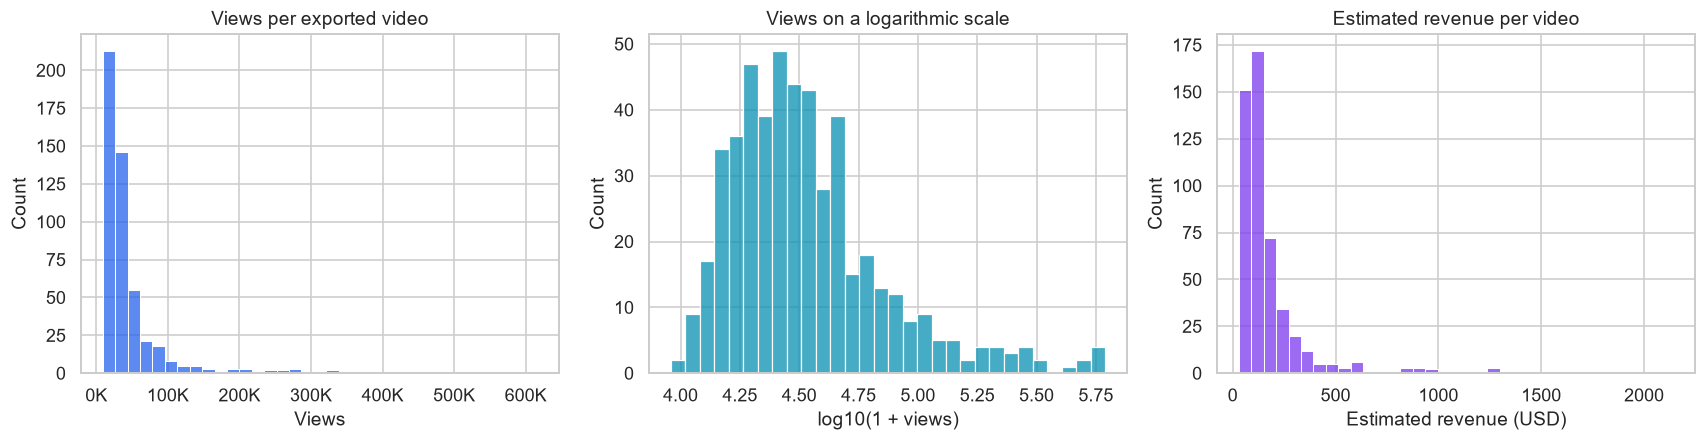

**Interpretation.** Median views are **29,144**, compared with a mean of **50,297**. The 10 most-viewed videos account for **18.5%** of subset views. This concentration is why category comparisons will show medians and sample sizes alongside totals. Extreme records remain in the main analysis unless a source error is confirmed.

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(videos_clean.views, bins=35, ax=axes[0], color='#2563eb')
axes[0].set(title='Views per exported video', xlabel='Views')
sns.histplot(np.log10(1 + videos_clean.views), bins=30, ax=axes[1], color='#0891b2')
axes[1].set(title='Views on a logarithmic scale', xlabel='log10(1 + views)')
sns.histplot(videos_clean.estimated_revenue_usd, bins=35, ax=axes[2], color='#7c3aed')
axes[2].set(title='Estimated revenue per video', xlabel='Estimated revenue (USD)')
finish_plot('01_distributions')
top10_share = videos_clean.nlargest(10, 'views').views.sum() / videos_clean.views.sum() * 100
note(f"**Interpretation.** Median views are **{videos_clean.views.median():,.0f}**, compared with a mean of "
     f"**{videos_clean.views.mean():,.0f}**. The 10 most-viewed videos account for **{top10_share:.1f}%** of subset views. "
     "This concentration is why category comparisons will show medians and sample sizes alongside totals. "
     "Extreme records remain in the main analysis unless a source error is confirmed.")

## 7. Viewing duration, reach and monetization
Each dot is one exported video. A symlog views axis displays the long tail while retaining zero values. These plots describe associations, not the effect of changing a thumbnail or extending a video.

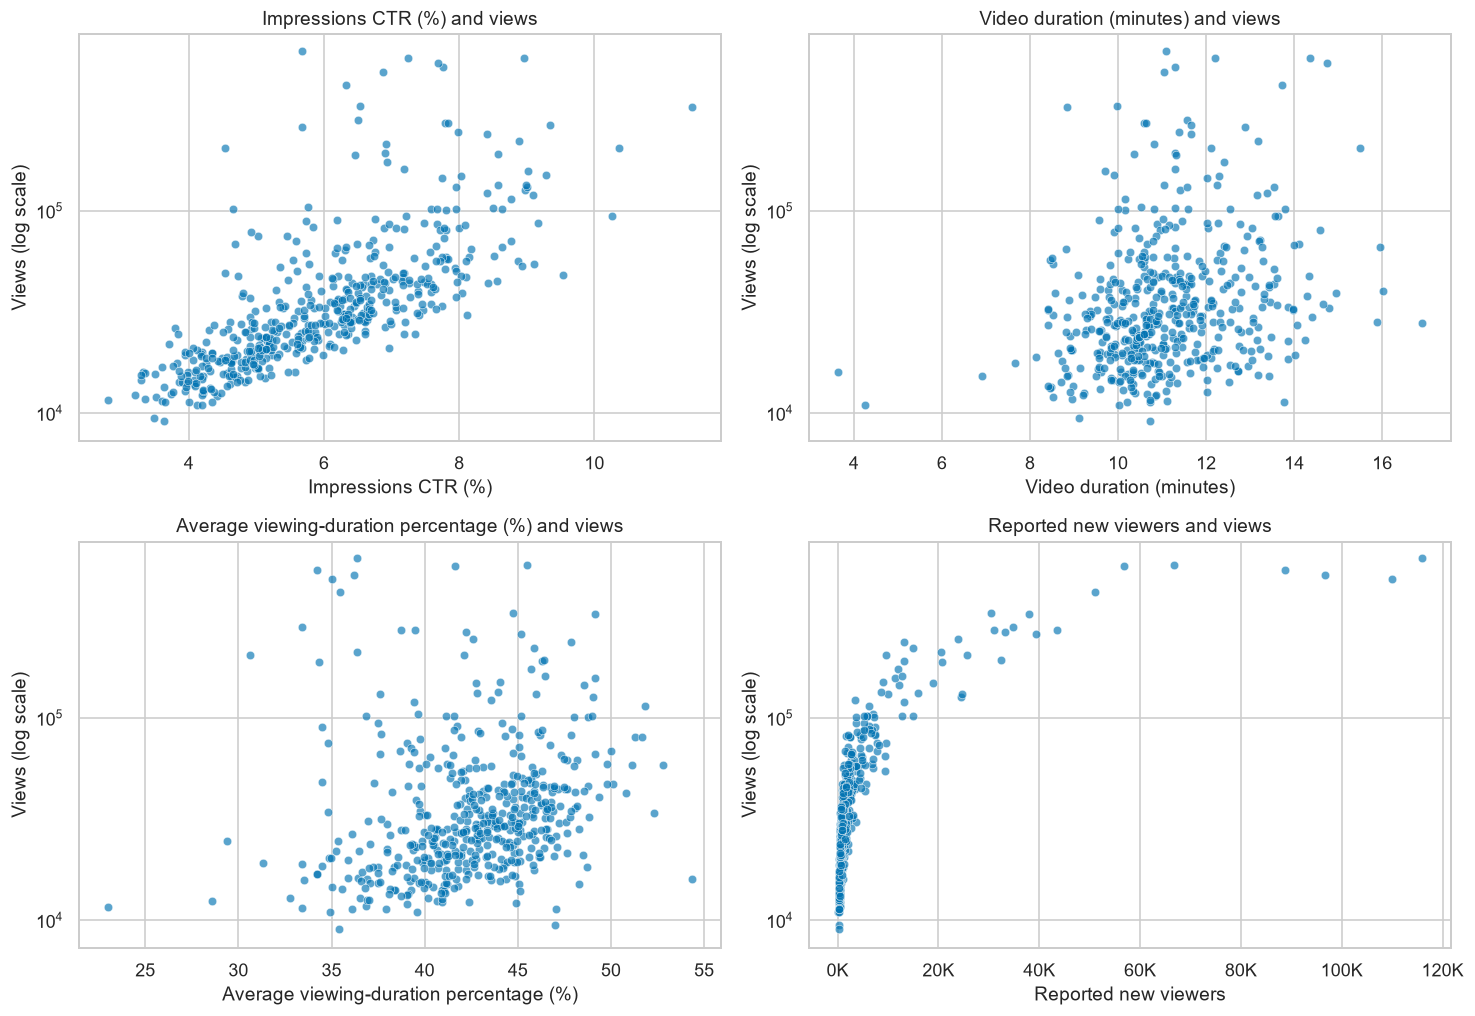

,x,y,n,pearson,spearman
0,impressions_ctr_percent,views,498,0.430,0.811
1,video_duration_minutes,views,498,0.184,0.300
2,average_view_duration_percent,views,498,-0.027,0.343
3,new_viewers,views,498,0.936,0.908
4,impressions,views,498,0.971,0.969
5,video_duration_seconds,average_view_duration_seconds,498,0.810,0.786
6,video_duration_seconds,average_view_duration_percent,498,-0.069,-0.028
7,views,estimated_revenue_usd,498,0.961,0.945


**impressions_ctr_percent vs. views:** Pearson **0.430**, Spearman **0.811** (n=498).

**video_duration_minutes vs. views:** Pearson **0.184**, Spearman **0.300** (n=498).

**average_view_duration_percent vs. views:** Pearson **-0.027**, Spearman **0.343** (n=498).

**new_viewers vs. views:** Pearson **0.936**, Spearman **0.908** (n=498).

**How to read this.** Pearson describes linear association and is sensitive to extreme values. Spearman compares ranks. Neither coefficient is a percentage of improvement or a causal estimate. New-viewer counts and views are both volume-related, so a strong relationship does not establish a content mechanism. CTR relates to eligible impressions; total views may have other sources. These are exploratory comparisons without significance claims or adjustment for publication age and topic.

In [14]:
relationships = [
    ('impressions_ctr_percent', 'Impressions CTR (%)'),
    ('video_duration_minutes', 'Video duration (minutes)'),
    ('average_view_duration_percent', 'Average viewing-duration percentage (%)'),
    ('new_viewers', 'Reported new viewers')
]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, label) in zip(axes.flat, relationships):
    sns.scatterplot(data=videos_clean, x=col, y='views', ax=ax, alpha=.65, s=28)
    ax.set(
    xlabel=label,
    ylabel='Views (log scale)',
    title=f'{label} and views'
    )
    ax.set_yscale('log')
    ax.set_ylim(
        videos_clean['views'].min() * 0.8,
        videos_clean['views'].max() * 1.2
    )
finish_plot('02_relationships_with_views')

pairs = [(c, 'views') for c, _ in relationships] + [
    ('impressions', 'views'),
    ('video_duration_seconds', 'average_view_duration_seconds'),
    ('video_duration_seconds', 'average_view_duration_percent'),
    ('views', 'estimated_revenue_usd')
]
correlation_rows = []
for x, y in pairs:
    valid = videos_clean[[x, y]].dropna()
    correlation_rows.append({'x': x, 'y': y, 'n': len(valid),
        'pearson': valid[x].corr(valid[y], method='pearson'),
        'spearman': valid[x].corr(valid[y], method='spearman')})
correlations = pd.DataFrame(correlation_rows)
display(correlations.round(3))
for row in correlations.iloc[:4].itertuples():
    note(f"**{row.x} vs. views:** Pearson **{row.pearson:.3f}**, Spearman **{row.spearman:.3f}** (n={row.n}).")
note("**How to read this.** Pearson describes linear association and is sensitive to extreme values. Spearman compares ranks. "
     "Neither coefficient is a percentage of improvement or a causal estimate. New-viewer counts and views are both volume-related, "
     "so a strong relationship does not establish a content mechanism. CTR relates to eligible impressions; total views may have other sources. "
     "These are exploratory comparisons without significance claims or adjustment for publication age and topic.")

In [15]:
ctr_row = correlations.loc[correlations.x.eq('impressions_ctr_percent')].iloc[0]
viewing_row = correlations.loc[correlations.x.eq('average_view_duration_percent')].iloc[0]
note(f"**Specific findings.** CTR has Pearson {ctr_row.pearson:.3f} and Spearman {ctr_row.spearman:.3f}. "
     "The stronger rank relationship means videos with higher CTR tend to rank higher in views, while the raw values follow a less consistent straight-line relationship. "
     f"Relative viewing duration has Pearson {viewing_row.pearson:.3f} and Spearman {viewing_row.spearman:.3f}; "
     "the difference shows why neither one coefficient nor one visual summary should stand alone. "
     "Inspect the sensitivity results next before drawing a practical conclusion.")

**Specific findings.** CTR has Pearson 0.430 and Spearman 0.811. The stronger rank relationship means videos with higher CTR tend to rank higher in views, while the raw values follow a less consistent straight-line relationship. Relative viewing duration has Pearson -0.027 and Spearman 0.343; the difference shows why neither one coefficient nor one visual summary should stand alone. Inspect the sensitivity results next before drawing a practical conclusion.

## 8. Sensitivity to the most-viewed videos
We repeat selected correlations after excluding the largest one and the largest five videos by views. This tests dependence on extreme records; it is not a reason to discard those records. The full dataset remains the primary result.

In [10]:
sensitivity_rows = []
ordered = videos_clean.sort_values(['views','video_id'], ascending=[False,True])
for remove_n in [0, 1, 5]:
    subset = ordered.iloc[remove_n:]
    for x, _ in relationships:
        valid = subset[[x,'views']].dropna()
        sensitivity_rows.append({'excluded_top_n': remove_n, 'metric': x, 'n': len(valid),
            'pearson': valid[x].corr(valid.views), 'spearman': valid[x].corr(valid.views, method='spearman')})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(3))
spans = sensitivity.groupby('metric')[['pearson','spearman']].agg(lambda s: s.max()-s.min())
display(spans.rename(columns=lambda c: c+'_range').round(3))
note('**Interpretation.** Larger coefficient ranges indicate stronger dependence on the top-viewed records. '
     'Small ranges support stability only for these exclusions; they do not rule out confounding, selection bias or other influential observations.')

,excluded_top_n,metric,n,pearson,spearman
0,0,impressions_ctr_percent,498,0.430,0.811
1,0,video_duration_minutes,498,0.184,0.300
2,0,average_view_duration_percent,498,-0.027,0.343
3,0,new_viewers,498,0.936,0.908
4,1,impressions_ctr_percent,497,0.462,0.814
5,1,video_duration_minutes,497,0.196,0.300
6,1,average_view_duration_percent,497,-0.004,0.350
7,1,new_viewers,497,0.931,0.907
8,5,impressions_ctr_percent,493,0.506,0.811
9,5,video_duration_minutes,493,0.154,0.289


,pearson_range,spearman_range
metric,,
average_view_duration_percent,0.080,0.023
impressions_ctr_percent,0.076,0.003
new_viewers,0.033,0.003
video_duration_minutes,0.042,0.011


**Interpretation.** Larger coefficient ranges indicate stronger dependence on the top-viewed records. Small ranges support stability only for these exclusions; they do not rule out confounding, selection bias or other influential observations.

## 9. Duration trade-offs and the revenue ratio
The duration percentage contains video length in its denominator. Its relationship with length can therefore have a mathematical component. Inspect absolute average seconds alongside the percentage.

Revenue per 1,000 views and absolute revenue answer different questions. We report both the median video ratio and the ratio of aggregate revenue to aggregate views; the latter weights videos by their views.

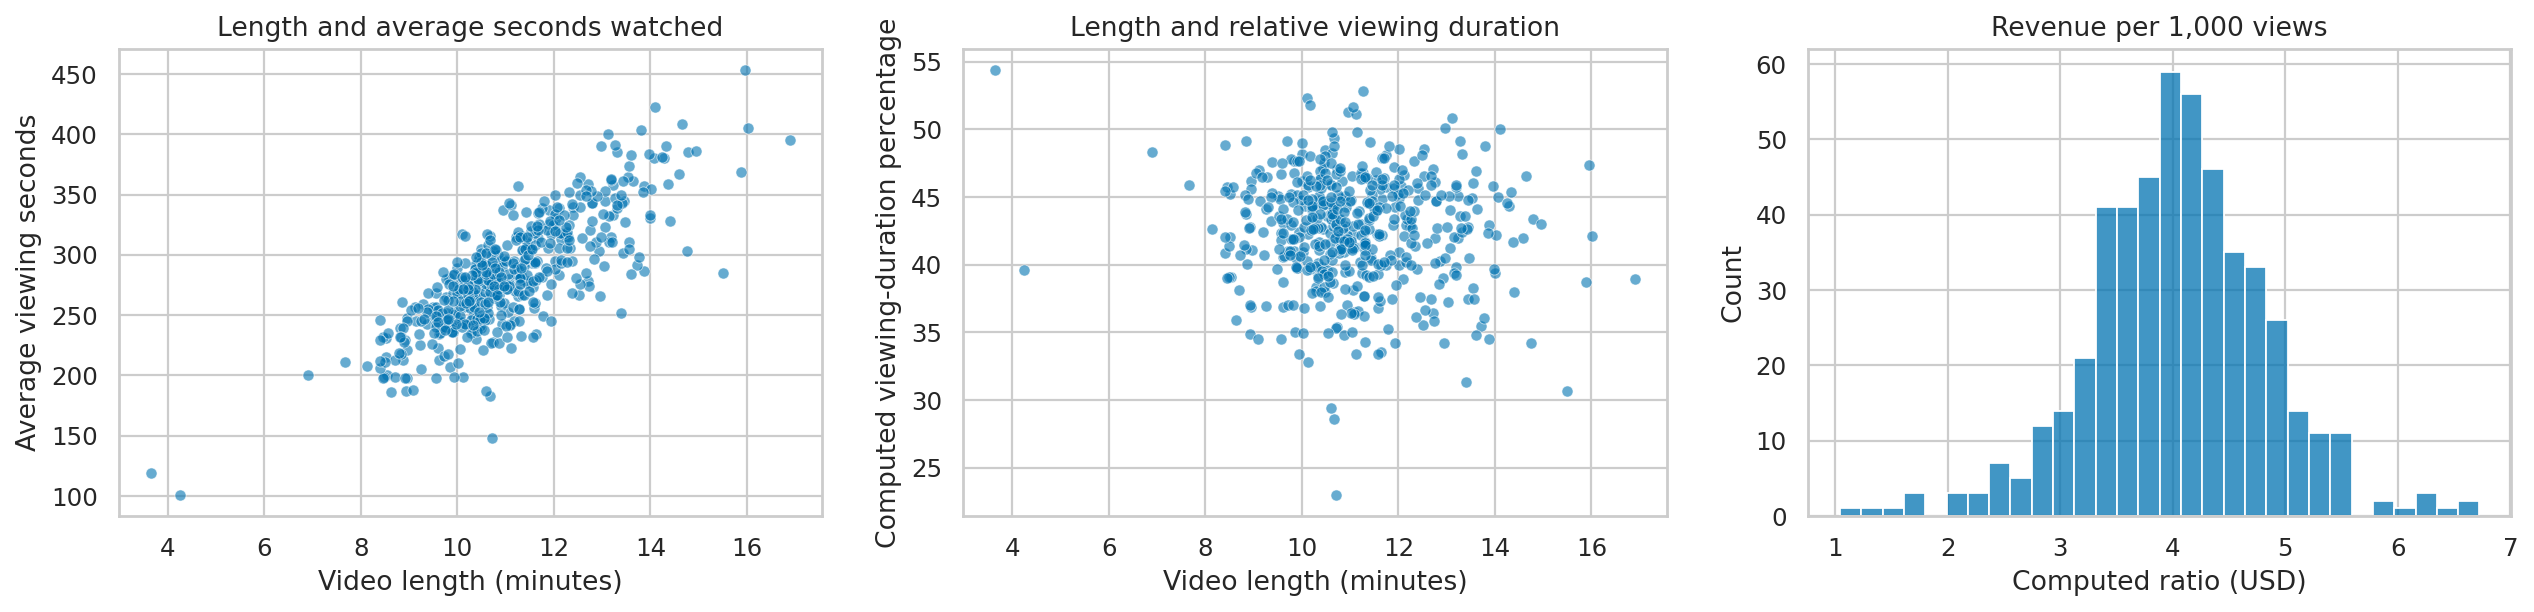

**Interpretation.** Median video length is **10.88 minutes**; median average viewing duration is **279 seconds**, and median computed viewing-duration percentage is **42.8%**. The aggregate revenue ratio is **USD 3.66 per 1,000 views**, versus a median individual-video ratio of **USD 4.04**. These separate medians need not algebraically reconcile. None of these measures establishes profit or an optimal causal video length.

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=videos_clean, x='video_duration_minutes', y='average_view_duration_seconds', ax=axes[0], alpha=.6, s=25)
axes[0].set(title='Length and average seconds watched', xlabel='Video length (minutes)', ylabel='Average viewing seconds')
sns.scatterplot(data=videos_clean, x='video_duration_minutes', y='average_view_duration_percent', ax=axes[1], alpha=.6, s=25)
axes[1].set(title='Length and relative viewing duration', xlabel='Video length (minutes)', ylabel='Computed viewing-duration percentage')
sns.histplot(videos_clean.estimated_revenue_per_1000_views_usd, bins=30, ax=axes[2])
axes[2].set(title='Revenue per 1,000 views', xlabel='Computed ratio (USD)')
finish_plot('03_duration_and_monetization')
aggregate_ratio = videos_clean.estimated_revenue_usd.sum() / videos_clean.views.sum() * 1000
note(f"**Interpretation.** Median video length is **{videos_clean.video_duration_minutes.median():.2f} minutes**; "
     f"median average viewing duration is **{videos_clean.average_view_duration_seconds.median():.0f} seconds**, "
     f"and median computed viewing-duration percentage is **{videos_clean.average_view_duration_percent.median():.1f}%**. "
     f"The aggregate revenue ratio is **USD {aggregate_ratio:.2f} per 1,000 views**, versus a median individual-video ratio of "
     f"**USD {videos_clean.estimated_revenue_per_1000_views_usd.median():.2f}**. "
     "These separate medians need not algebraically reconcile. None of these measures establishes profit or an optimal causal video length.")

## Video-level examples for qualitative follow-up
The top-viewed and highest-ratio lists are different rankings. The revenue-ratio shortlist below requires at least the dataset's median views, a transparent descriptive screen to avoid highlighting tiny denominators. It is not a statistical cutoff or a final recommendation. Review actual content before explaining why a video performed well.

In [12]:
example_columns = ['video_id','video_title','publish_date','views','estimated_revenue_usd','impressions_ctr_percent','average_view_duration_percent','estimated_revenue_per_1000_views_usd']
note('**Ten most-viewed exported videos**')
display(videos_clean.nlargest(10, 'views')[example_columns].round(3))
note('**Highest computed revenue ratios among videos at or above median views**')
display(videos_clean.loc[videos_clean.views.ge(videos_clean.views.median())].nlargest(10, 'estimated_revenue_per_1000_views_usd')[example_columns].round(3))

**Ten most-viewed exported videos**

,video_id,video_title,publish_date,views,estimated_revenue_usd,impressions_ctr_percent,average_view_duration_percent,estimated_revenue_per_1000_views_usd
308,Ja_Z8TB9qio,4 MEJORES TES PARA DORMIR RAPIDO Y ELIMINAR EL INSOMNIO,2025-06-11,616088,2142.443,5.67,36.391,3.477
422,c6Q0mnB7364,JUGO DE SABILA EN AYUNAS 5 NUEVOS BENEFICIOS DESCUBIERTOS DEL...,2025-02-11,566561,1395.394,8.96,45.492,2.463
427,Fe-JJPqH1K0,SEMILLA DE AGUACATE MOLIDA TODOS LOS DIAS - RECETA SECRETA RE...,2025-02-06,563104,1920.213,7.24,41.647,3.410
321,WCjx_DpM7pA,1 CUCHARADA DE ACEITE DE OLIVA CON LIMON EN AYUNAS TODOS LOS ...,2025-05-29,536992,1699.627,7.68,34.237,3.165
266,PDHvDuJaevM,"AGUA CON BICARBONATO EN AYUNAS - Beneficios, Para Que Sirve Y...",2025-07-23,508434,1280.787,7.76,36.189,2.519
400,oi8ZRpcXtHM,Agua De Avena En Ayunas Por 1 Semana - Para Qué Sirve? - Bene...,2025-03-07,483041,1280.744,6.88,35.045,2.651
101,AILe7BdL9Q8,1 CUCHARADA DE ACEITE DE OLIVA CON LIMON EN AYUNAS - Para Que...,2026-01-29,415994,1240.615,6.33,35.480,2.982
177,xxsRDF-3gCA,TE DE ROMERO EN AYUNAS - Para Que Sirve? - Beneficios Para Tu...,2025-11-10,328694,924.714,6.53,44.741,2.813
458,ljr9dpCcK4Q,LA PRÓXIMA EPIDEMIA! - HMPV EL NUEVO VIRUS CHINO DEL 2025,2025-01-06,324970,424.265,11.44,49.153,1.306
347,oswjabhCopQ,CAFE CON CANELA EN AYUNAS - Beneficios Y Contraindicaciones P...,2025-05-01,279190,947.251,6.50,33.429,3.393


**Highest computed revenue ratios among videos at or above median views**

,video_id,video_title,publish_date,views,estimated_revenue_usd,impressions_ctr_percent,average_view_duration_percent,estimated_revenue_per_1000_views_usd
482,cswITHbggmk,Café Con Miel En Ayunas ¿Para Qué Sirve? - Beneficios Para Tu...,2024-12-13,159705,930.983,7.19,46.460,5.829
160,NqYvkO8qP8s,"TE DE CLAVO DE OLOR EN AYUNAS - Para Que Sirve, Beneficios Y ...",2025-11-27,33793,187.362,6.45,52.310,5.544
317,kOHHyNn_euM,JUGO DE MANZANA VERDE CON ESPINACA - ¿Para Qué Sirve?,2025-06-02,50358,278.767,7.95,45.202,5.536
262,DeJcWpNmBNk,AGUA DE PEPINO CON CHÍA - ¿Para Qué Sirve? - Beneficios Para ...,2025-07-27,35236,194.800,5.34,42.751,5.528
332,f_L_Uij4pFw,COMO SER MAS INTELIGENTE Y AGRANDAR TU CEREBRO,2025-05-16,51512,283.500,7.79,44.951,5.504
407,_AEp_5tx2Z8,5 PASOS PARA BAJAR DE PESO FACIL EN 2 SEMANAS,2025-02-26,33270,182.943,7.07,43.593,5.499
54,uoMwBO1dtB4,NO TOMES CAFÉ - Contraindicaciones De Tomar Cafe Que Debes Co...,2026-03-17,35880,197.228,6.20,45.739,5.497
489,FOVfgRQ321E,COMO DORMIR BIEN COMO UN BEBE 2025 - Elimina El Insomnio Y La...,2024-12-06,44867,245.081,6.73,46.961,5.462
176,zxoJoBG4jwQ,NO TOMES CAFE! - Contraindicaciones Y Enfermedades Por Consum...,2025-11-11,31057,167.576,6.58,43.411,5.396
344,DrcEJ0Hni0I,COMO BAJAR EL AZUCAR PARA SIEMPRE - Técnicas Y Alimentos Para...,2025-05-04,39143,207.349,6.50,43.032,5.297


## 10. Publication cohorts
These charts group the exported videos by publication month. They show publication volume and median accumulated/export-window views for each cohort. They do **not** show how many views the channel received each month.

The last cohort may be incomplete. We do not divide by days since publication because the exact metric window and extraction cutoff have not been confirmed; daily averages would also assume a rate pattern that may be unrealistic.

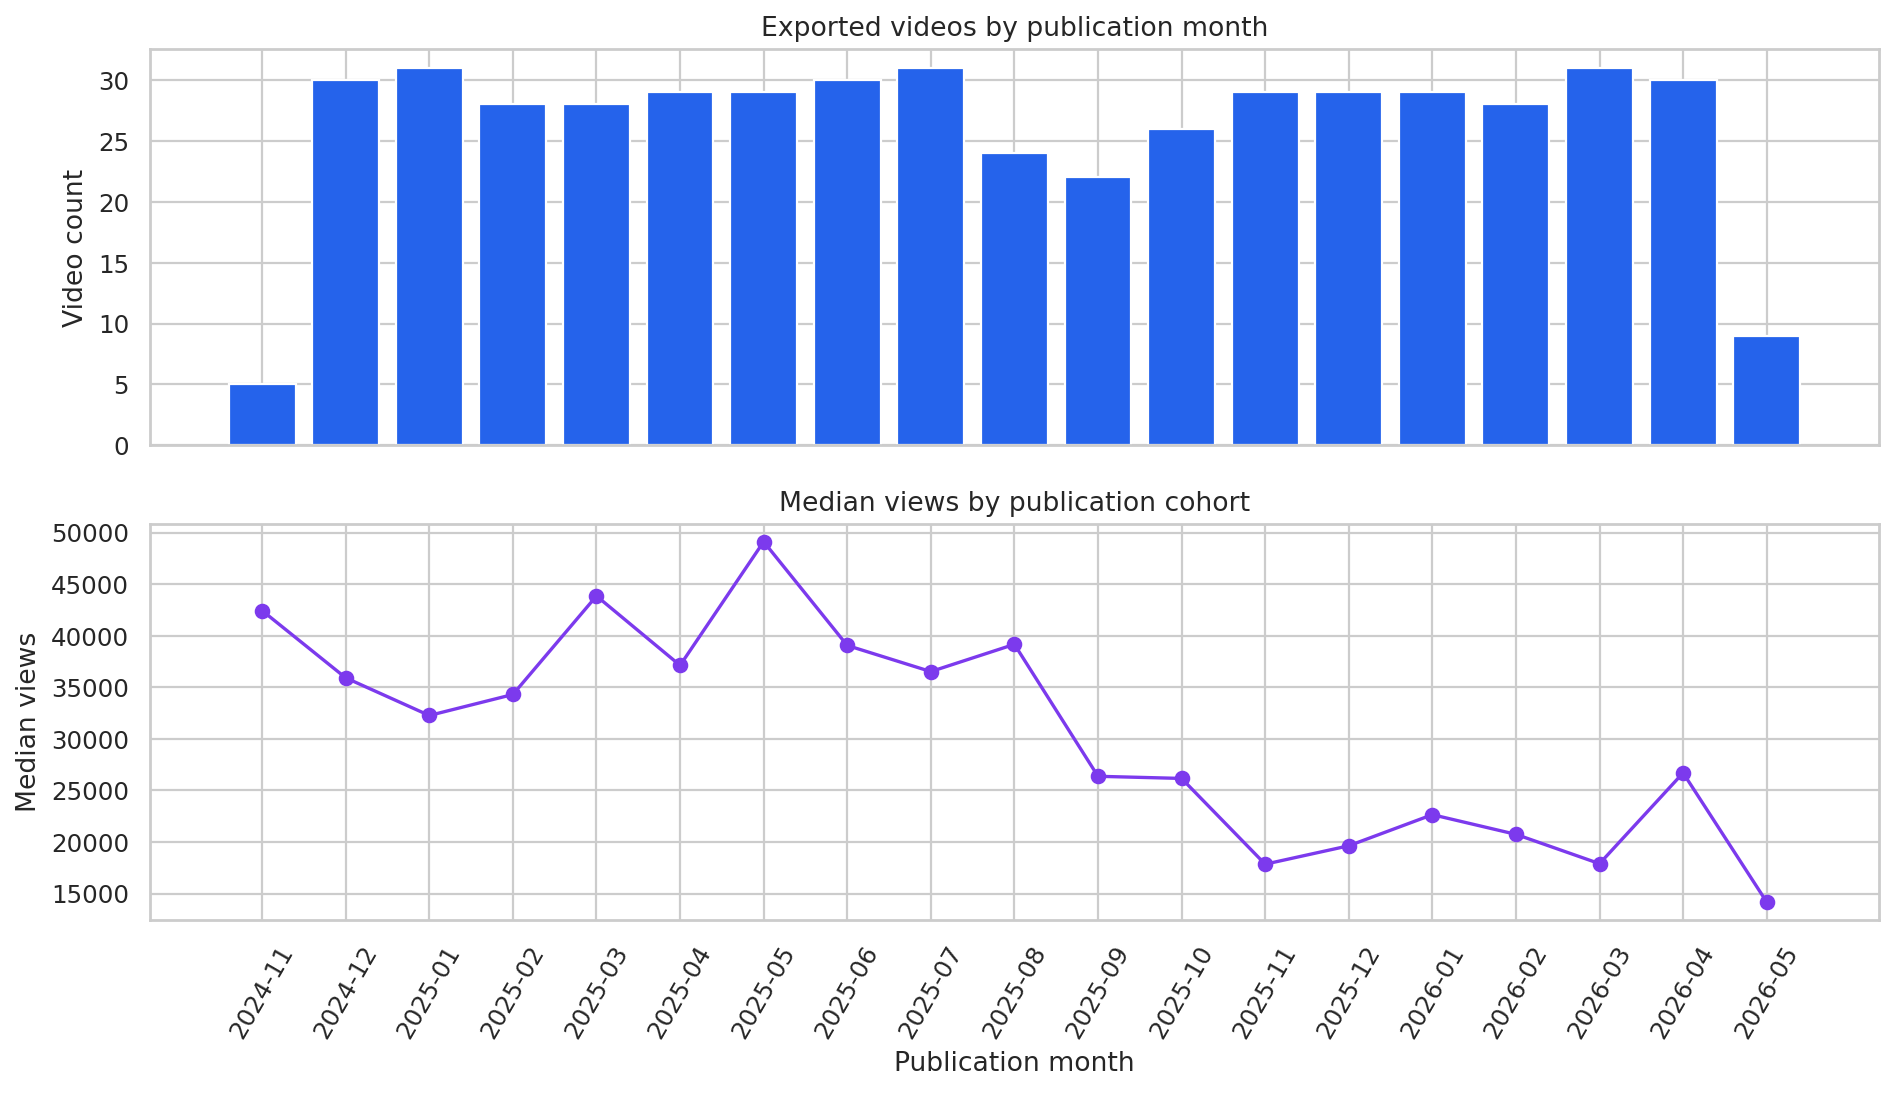

,publish_month,video_count,median_views
0,2024-11,5,42433.0
1,2024-12,30,35913.5
2,2025-01,31,32265.0
3,2025-02,28,34301.0
4,2025-03,28,43853.0
5,2025-04,29,37123.0
6,2025-05,29,49116.0
7,2025-06,30,39054.0
8,2025-07,31,36522.0
9,2025-08,24,39163.5


**Interpretation.** The highest observed cohort median is **2025-05**, with **49,116 views** across **29 videos**. This is descriptive: differences can reflect exposure time, content mix, selection and distribution conditions, not a change in channel performance alone.

In [13]:
cohorts = videos_clean.groupby('publish_month').agg(video_count=('video_id','size'), median_views=('views','median')).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].bar(cohorts.publish_month, cohorts.video_count, color='#2563eb')
axes[0].set(title='Exported videos by publication month', ylabel='Video count')
axes[1].plot(cohorts.publish_month, cohorts.median_views, marker='o', color='#7c3aed')
axes[1].set(title='Median views by publication cohort', ylabel='Median views', xlabel='Publication month')
axes[1].tick_params(axis='x', rotation=60)
finish_plot('04_publication_cohorts')
display(cohorts)
best_cohort = cohorts.loc[cohorts.median_views.idxmax()]
note(f"**Interpretation.** The highest observed cohort median is **{best_cohort['publish_month']}**, "
     f"with **{best_cohort.median_views:,.0f} views** across **{int(best_cohort.video_count)} videos**. "
     "This is descriptive: differences can reflect exposure time, content mix, selection and distribution conditions, not a change in channel performance alone.")

# C — Construct
## 11. Construct a transparent content taxonomy
This phase constructs reusable analytical features, summaries and review files. It does **not** fit a predictive model: a defensible prediction target and common observation window are not established.

### Category rules
1. Normalize accents, spacing and case, retaining original titles.
2. Identify explicit health-topic keywords. A single detected topic takes priority over ingredients.
3. If several health topics are detected, leave the primary category unresolved for manual review.
4. If no specific health topic is detected but an ingredient, food or supplement is explicit, propose `Food, Herbs & Supplements`.
5. Otherwise leave the video `Unclassified`.

This deliberately broad food category can dominate the dataset and conceal subtopics. It is a starting taxonomy, not a proven optimal segmentation. Proposed assignments are not verified by watching the videos. Generic phrases such as “health and beauty” do not establish a skin-health topic.

**Review contract:** `proposed_category` preserves the automated suggestion; `final_category` is a human override; `review_status` records approval. A proposal may be approved unchanged. Set status to `Reviewed` only after verification. Topic and live/uploaded format are separate fields.

In [14]:
def normalize_title(value):
    value = unicodedata.normalize('NFKD', str(value)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'\s+', ' ', value).strip()

# Word boundaries reduce substring errors; accents are removed before matching.
topic_rules = {
    'Digestive Health': r'\b(digestion|digestiv\w*|estomago|gastritis|reflujo|colon|intestin\w*|estrenimiento|helicobacter|pylori)\b',
    'Liver & Gallbladder Health': r'\b(higado|hepat\w*|vesicula|biliar\w*)\b',
    'Kidney & Urinary Health': r'\b(rinon\w*|renal\w*|vejiga|urinari\w*|orina|prostata)\b',
    'Heart & Circulation': r'\b(corazon|cardiac\w*|circulacion|arteri\w*|hipertension|presion arterial|varices|infarto)\b',
    'Metabolic & Hormonal Health': r'\b(diabetes|diabetic\w*|insulina|glucosa|azucar en la sangre|colesterol|trigliceridos|tiroides|hormon\w*|obesidad|adelgazar|bajar de peso)\b',
    'Brain & Mental Health': r'\b(cerebro|cerebral|memoria|alzheimer|demencia|ansiedad|depresion|estres|inteligente)\b',
    'Sleep Health': r'\b(insomnio|dormir|sueno|ronquidos)\b',
    'Bone, Joint & Muscle Health': r'\b(huesos|osteoporosis|articul\w*|artritis|rodilla\w*|musculo\w*|muscular\w*|espalda)\b',
    'Skin & Hair Health': r'\b(piel|cabello|acne|arrugas|calvicie|alopecia|manchas en la cara)\b',
    'Eye & Ear Health': r'\b(ojos|vista|vision|oido\w*|cataratas|tinnitus)\b',
    'Respiratory & Immune Health': r'\b(pulmon\w*|respiratori\w*|asma|bronqu\w*|tos|gripe|resfriado|inmun\w*|defensas)\b',
    'Cancer': r'\b(cancer|anticancer\w*|tumor\w*)\b',
    'Infections & Parasites': r'\b(parasito\w*|infeccion\w*|bacteria\w*)\b',
    'Oral Health': r'\b(dientes|encias|bucal|caries|halitosis)\b',
    "Women's Health": r'\b(menopausia|ovario\w*|menstrual|endometriosis)\b',
    'Medications & Vaccines': r'\b(vacuna\w*|medicamento\w*|ozempic|tylenol|ibuprofeno)\b',
    'Environmental Health & Toxicology': r'\b(contaminacion|pesticida\w*|microplastico\w*|metales pesados)\b'
}
food_rule = r'\b(jugo|zumo|te|agua de|agua con|aceite|vinagre|vitamina\w*|colageno|suplemento\w*|semilla\w*|fruta\w*|verdura\w*|avena|ajo|cebolla|limon|jengibre|curcuma|canela|miel|linaza|chia|perejil|cilantro|romero|laurel|clavo|repollo|papaya|pepino|kiwi|manzana|espinaca|remolacha|zanahoria|almendra\w*|cafe|gelatina|bicarbonato|aloe|nopal|aguacate|huevo|leche|magnesio|zinc|selenio|potasio|probiotico\w*)\b'

def classify_title(title):
    text = normalize_title(title)
    hits = [category for category, pattern in topic_rules.items() if re.search(pattern, text)]
    if len(hits) == 1:
        return hits[0], 'Proposed', 'One explicit topic detected; title-only proposal.', '; '.join(hits)
    if len(hits) > 1:
        return 'Unclassified', 'Needs review', 'Multiple topics detected; choose primary focus after review.', '; '.join(hits)
    if re.search(food_rule, text):
        return 'Food, Herbs & Supplements', 'Proposed', 'Ingredient/food wording without a unique specific health topic.', ''
    return 'Unclassified', 'Needs review', 'Insufficient explicit topic in title.', ''

proposals = pd.DataFrame(videos_clean.video_title.map(classify_title).tolist(),
    columns=['proposed_category','review_status','classification_note','detected_topics'], index=videos_clean.index)
category_draft = pd.concat([videos_clean[['video_id','video_title','video_url']], proposals], axis=1)
category_draft['final_category'] = ''
category_draft['classification_method'] = 'Keyword rules on title; no video verification'
review_path = processed_dir / 'category_review.csv'
if review_path.exists():
    previous = pd.read_csv(review_path, dtype={'video_id':'string'}, keep_default_na=False)
    assert previous.video_id.is_unique, 'Duplicate IDs in review file.'
    assert set(previous.video_id).issubset(set(videos_clean.video_id)), 'Review file includes IDs absent from this workbook; reconcile before reuse.'
    required_review = {'video_id','final_category','review_status'}
    assert required_review.issubset(previous.columns), 'Review file schema incomplete.'
    previous = previous.set_index('video_id')
    for col in ['final_category','review_status','classification_note']:
        if col in previous:
            mapped = category_draft.video_id.map(previous[col])
            category_draft[col] = mapped.fillna(category_draft[col])
else:
    category_draft.to_csv(review_path, index=False, encoding='utf-8-sig')

allowed_categories = set(topic_rules) | {'Food, Herbs & Supplements','General Health & Lifestyle','Medical Humor & Commentary','Unclassified'}
final_values = category_draft.final_category.fillna('').astype(str).str.strip()
assert set(final_values[final_values.ne('')]).issubset(allowed_categories), 'Unknown final category: update the taxonomy deliberately.'
assert set(category_draft.review_status).issubset({'Proposed','Needs review','Reviewed'}), 'Unexpected review status.'
category_draft['content_category'] = final_values.where(final_values.ne(''), category_draft.proposed_category)
category_draft['category_is_reviewed'] = category_draft.review_status.eq('Reviewed') & category_draft.content_category.ne('Unclassified')
videos_clean = videos_clean.merge(category_draft.drop(columns=['video_title','video_url']), on='video_id', how='left', validate='one_to_one')
assert len(videos_clean) == len(category_draft)
needs_review = videos_clean.loc[~videos_clean.category_is_reviewed,
    ['video_id','video_title','video_url','proposed_category','final_category','review_status','classification_note','detected_topics']]
category_counts = videos_clean.content_category.value_counts().rename_axis('content_category').reset_index(name='video_count')
display(category_counts)
display(needs_review.head(12))
note(f"**Coverage.** {videos_clean.content_category.ne('Unclassified').sum()} of {len(videos_clean)} videos have a usable proposed/overridden category; "
     f"{videos_clean.content_category.eq('Unclassified').sum()} remain unclassified. "
     f"Only **{int(videos_clean.category_is_reviewed.sum())}** are explicitly marked Reviewed. "
     "Every remaining proposal still needs validation. The following category charts are exploratory, not final stakeholder rankings.")

,content_category,video_count
0,"Food, Herbs & Supplements",347
1,Unclassified,90
2,Metabolic & Hormonal Health,10
3,Sleep Health,8
4,Digestive Health,8
5,Kidney & Urinary Health,6
6,Skin & Hair Health,5
7,Liver & Gallbladder Health,5
8,"Bone, Joint & Muscle Health",4
9,Eye & Ear Health,4


,video_id,video_title,video_url,proposed_category,final_category,review_status,classification_note,detected_topics
0,gQXwLdGldFY,"JUGO DE REPOLLO MORADO EN AYUNAS - Para Que Sirve, Beneficios...",https://www.youtube.com/watch?v=gQXwLdGldFY,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
1,1L-yEOCMv3I,"TE DE JENGIBRE CON LIMON TODOS LOS DIAS - Para Que Sirve, Ben...",https://www.youtube.com/watch?v=1L-yEOCMv3I,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
2,zqZ3xqS1v08,PODEROSO JUGO DE BETABEL EN AYUNAS - ¿Para Qué Sirve La Remol...,https://www.youtube.com/watch?v=zqZ3xqS1v08,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
3,gVxROQYr1uA,"TE DE CEBOLLA ROJA TODOS LOS DIAS - Para Que Sirve, Beneficio...",https://www.youtube.com/watch?v=gVxROQYr1uA,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
4,noj0r31-vqQ,"TE DE CANELA Y CLAVO DE OLOR TODOS LOS DIAS - Para Que Sirve,...",https://www.youtube.com/watch?v=noj0r31-vqQ,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
5,IqTCD57NfwY,DIENTE DE LEON TODOS LOS DIAS - Para Que Sirve El Te? Benefic...,https://www.youtube.com/watch?v=IqTCD57NfwY,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
6,4grLyMBgp2A,Café Con Miel En Ayunas ¿Para Qué Sirve? - Beneficios Para Tu...,https://www.youtube.com/watch?v=4grLyMBgp2A,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
7,SpBkdhRxwz4,REVELADO! MEJOR DESTRUCTOR DE AZUCAR PARA LA DIABETES Y PRE D...,https://www.youtube.com/watch?v=SpBkdhRxwz4,Metabolic & Hormonal Health,,Proposed,One explicit topic detected; title-only proposal.,Metabolic & Hormonal Health
8,HWKY8AKWGNM,"SABILA CON MIEL TODOS LOS DIAS - Para Que Sirve, Beneficios Y...",https://www.youtube.com/watch?v=HWKY8AKWGNM,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,
9,X6_fePLL2Q8,AVENA CON CHIA PARA TODO - Beneficios Y Contraindicaciones Pa...,https://www.youtube.com/watch?v=X6_fePLL2Q8,"Food, Herbs & Supplements",,Proposed,Ingredient/food wording without a unique specific health topic.,


**Coverage.** 408 of 498 videos have a usable proposed/overridden category; 90 remain unclassified. Only **0** are explicitly marked Reviewed. Every remaining proposal still needs validation. The following category charts are exploratory, not final stakeholder rankings.

## 12. Category contribution and typical performance
We show both total contribution and median performance. A category may contribute more views because it contains more videos. A minimum of five videos is used for the main comparison to reduce one-video rankings, but five is not a guarantee of precision.

`Unclassified` remains in the full summary for coverage transparency and is excluded from topical rankings. Audience medians describe individual videos, not deduplicated people across a category.

,content_category,video_count,reviewed_count,total_views,median_views,total_revenue_usd,median_revenue_usd,median_new_viewers,median_returning_viewers,median_ctr_percent,median_view_duration_percent,median_revenue_per_1000_views_usd,aggregate_revenue_per_1000_views_usd,subset_views_share_percent,below_display_threshold
4,Eye & Ear Health,4,0,388082,46020.5,1492.741,210.606,1525.0,38717.0,7.765,44.720,4.580,3.846,1.549,True
1,Brain & Mental Health,4,0,167933,40357.0,786.032,204.846,1357.5,33882.0,7.145,43.214,4.342,4.681,0.670,True
12,Sleep Health,8,0,858014,39640.0,3134.070,151.672,1143.5,32433.5,6.000,39.902,3.861,3.653,3.425,False
3,Digestive Health,8,0,251137,37188.5,937.813,113.264,1047.5,31073.5,6.410,44.426,3.610,3.734,1.003,False
9,Metabolic & Hormonal Health,10,0,431313,36206.5,2081.187,162.380,1237.0,30046.5,6.485,42.793,4.876,4.825,1.722,False
2,Cancer,4,0,115504,29923.0,456.770,115.424,810.0,25479.5,6.085,39.271,4.028,3.955,0.461,True
5,"Food, Herbs & Supplements",347,0,18488349,29558.0,67151.426,120.619,1064.0,24549.0,5.860,42.788,4.037,3.632,73.812,False
6,Heart & Circulation,1,0,28092,28092.0,123.783,123.783,633.0,23372.0,7.200,41.199,4.406,4.406,0.112,True
8,Liver & Gallbladder Health,5,0,369628,27929.0,1098.523,96.450,1351.0,23270.0,5.410,45.149,3.453,2.972,1.476,False
10,Respiratory & Immune Health,1,0,27842,27842.0,129.554,129.554,905.0,23369.0,6.070,46.230,4.653,4.653,0.111,True


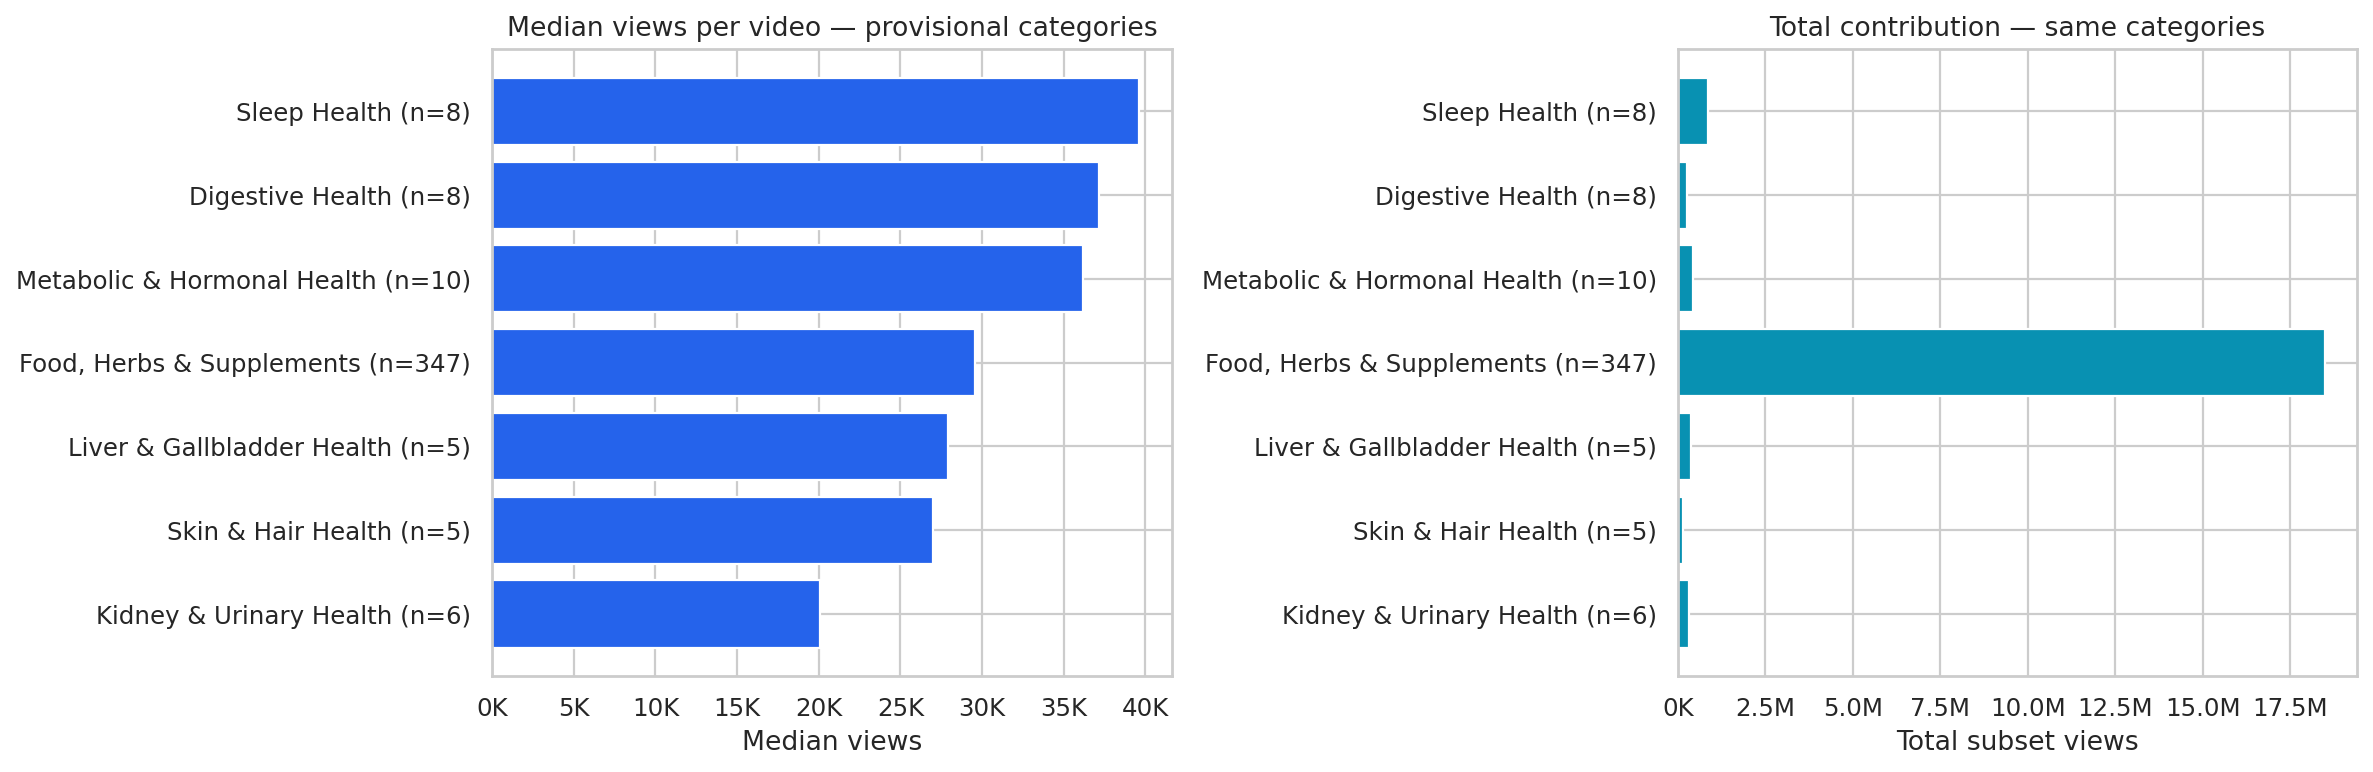

**Interpretation.** Among categories with at least 5 videos, **Sleep Health** has the highest observed median views (**39,640**, n=8). The right panel answers a different question: contribution to subset views. Category imbalance, provisional labels and publication timing prevent a causal topic recommendation.

In [15]:
category_summary = videos_clean.groupby('content_category').agg(
    video_count=('video_id','size'), reviewed_count=('category_is_reviewed','sum'),
    total_views=('views','sum'), median_views=('views','median'),
    total_revenue_usd=('estimated_revenue_usd','sum'), median_revenue_usd=('estimated_revenue_usd','median'),
    median_new_viewers=('new_viewers','median'), median_returning_viewers=('returning_viewers','median'),
    median_ctr_percent=('impressions_ctr_percent','median'),
    median_view_duration_percent=('average_view_duration_percent','median'),
    median_revenue_per_1000_views_usd=('estimated_revenue_per_1000_views_usd','median')
).reset_index()
category_summary['aggregate_revenue_per_1000_views_usd'] = category_summary.total_revenue_usd / category_summary.total_views.where(category_summary.total_views > 0) * 1000
category_summary['subset_views_share_percent'] = category_summary.total_views / videos_clean.views.sum() * 100
category_summary['below_display_threshold'] = category_summary.video_count < MIN_CATEGORY_N
category_summary = category_summary.sort_values('median_views', ascending=False)
display(category_summary.round(3))
ranked = category_summary.loc[(category_summary.video_count >= MIN_CATEGORY_N) & category_summary.content_category.ne('Unclassified')].sort_values('median_views')
if len(ranked):
    fig, axes = plt.subplots(1, 2, figsize=(15, max(5,len(ranked)*.48)))
    labels = ranked.content_category + ' (n=' + ranked.video_count.astype(str) + ')'
    axes[0].barh(labels, ranked.median_views, color='#2563eb')
    axes[0].set(title='Median views per video — provisional categories', xlabel='Median views')
    axes[1].barh(labels, ranked.total_views, color='#0891b2')
    axes[1].set(title='Total contribution — same categories', xlabel='Total subset views')
    finish_plot('05_category_median_vs_total')
    leader = ranked.iloc[-1]
    note(f"**Interpretation.** Among categories with at least {MIN_CATEGORY_N} videos, **{leader.content_category}** has the highest "
         f"observed median views (**{leader.median_views:,.0f}**, n={int(leader.video_count)}). "
         "The right panel answers a different question: contribution to subset views. Category imbalance, provisional labels and publication timing prevent a causal topic recommendation.")
else:
    note('No reviewed/proposed topic meets the display threshold; inspect the full summary instead.')

## 13. Category distributions and uncertainty from small groups
Boxplots show medians, the interquartile range and extreme observations. A log scale improves readability for positive views. Group counts are included; a single median alone would hide the spread and overlap.

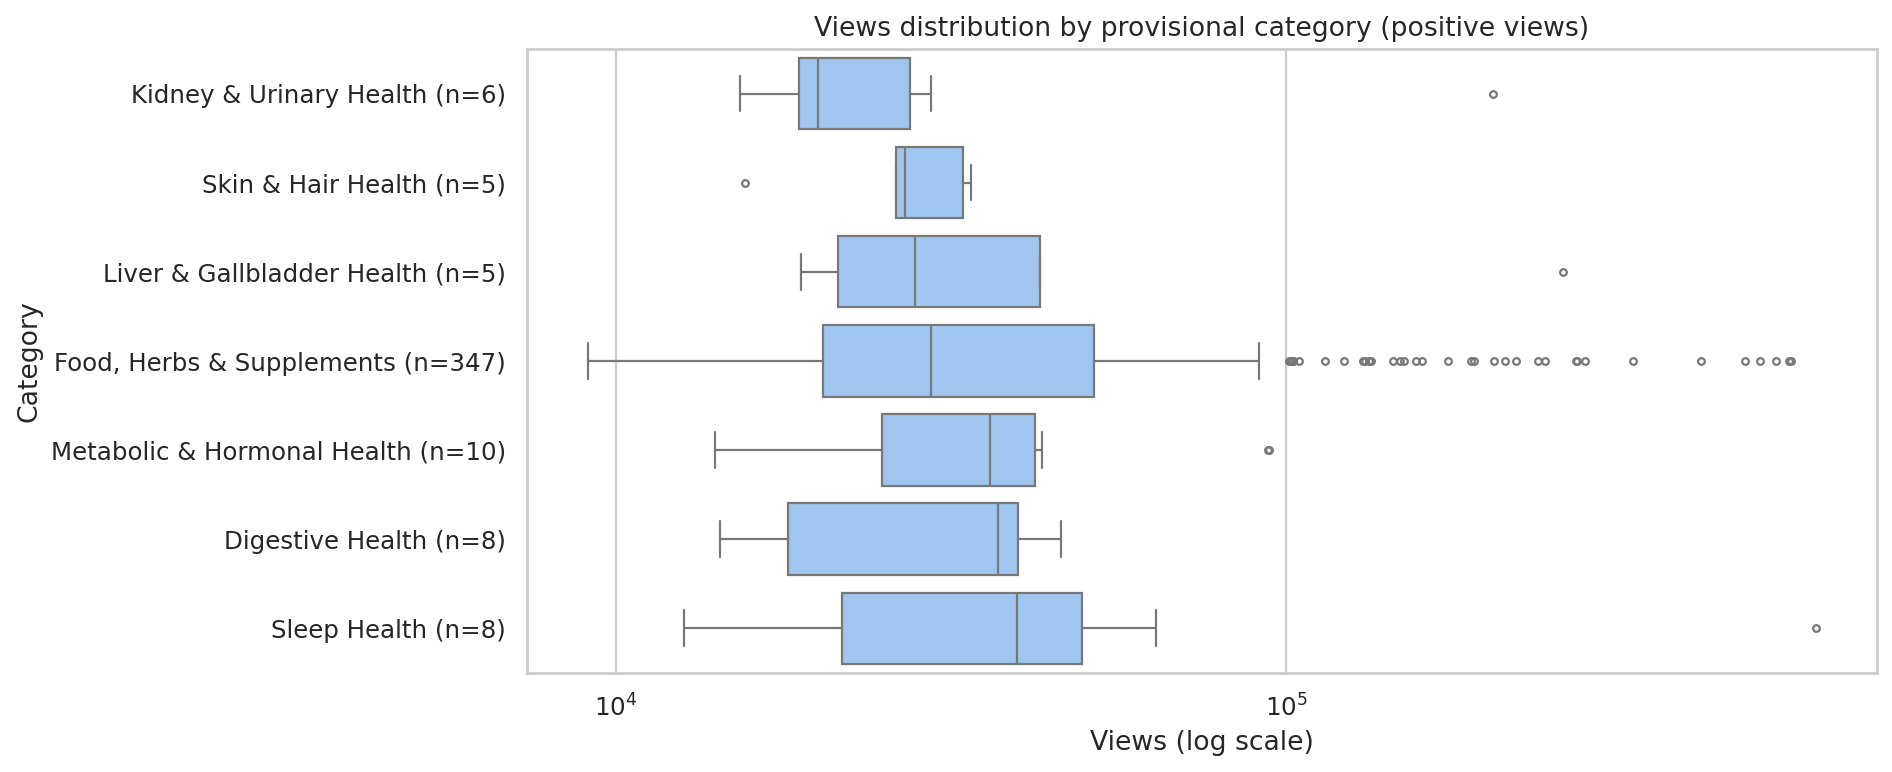

**Interpretation.** Wide boxes and long tails indicate substantial variation within topics. Overlap means the typical ranking does not apply to every video. Use these distributions to select videos for deeper review, not to promise the performance of a future upload.

In [16]:
if len(ranked):
    plot_data = videos_clean.loc[videos_clean.content_category.isin(ranked.content_category) & videos_clean.views.gt(0)]
    plt.figure(figsize=(12,max(5,len(ranked)*.5)))
    ax = sns.boxplot(data=plot_data, x='views', y='content_category', order=ranked.content_category, color='#93c5fd', fliersize=3)
    ax.set_xscale('log')
    ax.set(title='Views distribution by provisional category (positive views)', xlabel='Views (log scale)', ylabel='Category')
    ax.set_yticks(range(len(ranked)), labels=ranked.content_category + ' (n=' + ranked.video_count.astype(str) + ')')
    finish_plot('06_category_distributions')
    note('**Interpretation.** Wide boxes and long tails indicate substantial variation within topics. Overlap means the typical ranking does not apply to every video. '
         'Use these distributions to select videos for deeper review, not to promise the performance of a future upload.')

## 14. Reach and monetization by category
The two panels compare the typical revenue per video and the aggregate revenue per 1,000 views. The ratio of sums is intentionally different from the median of per-video ratios. No profitability claim is possible without costs.

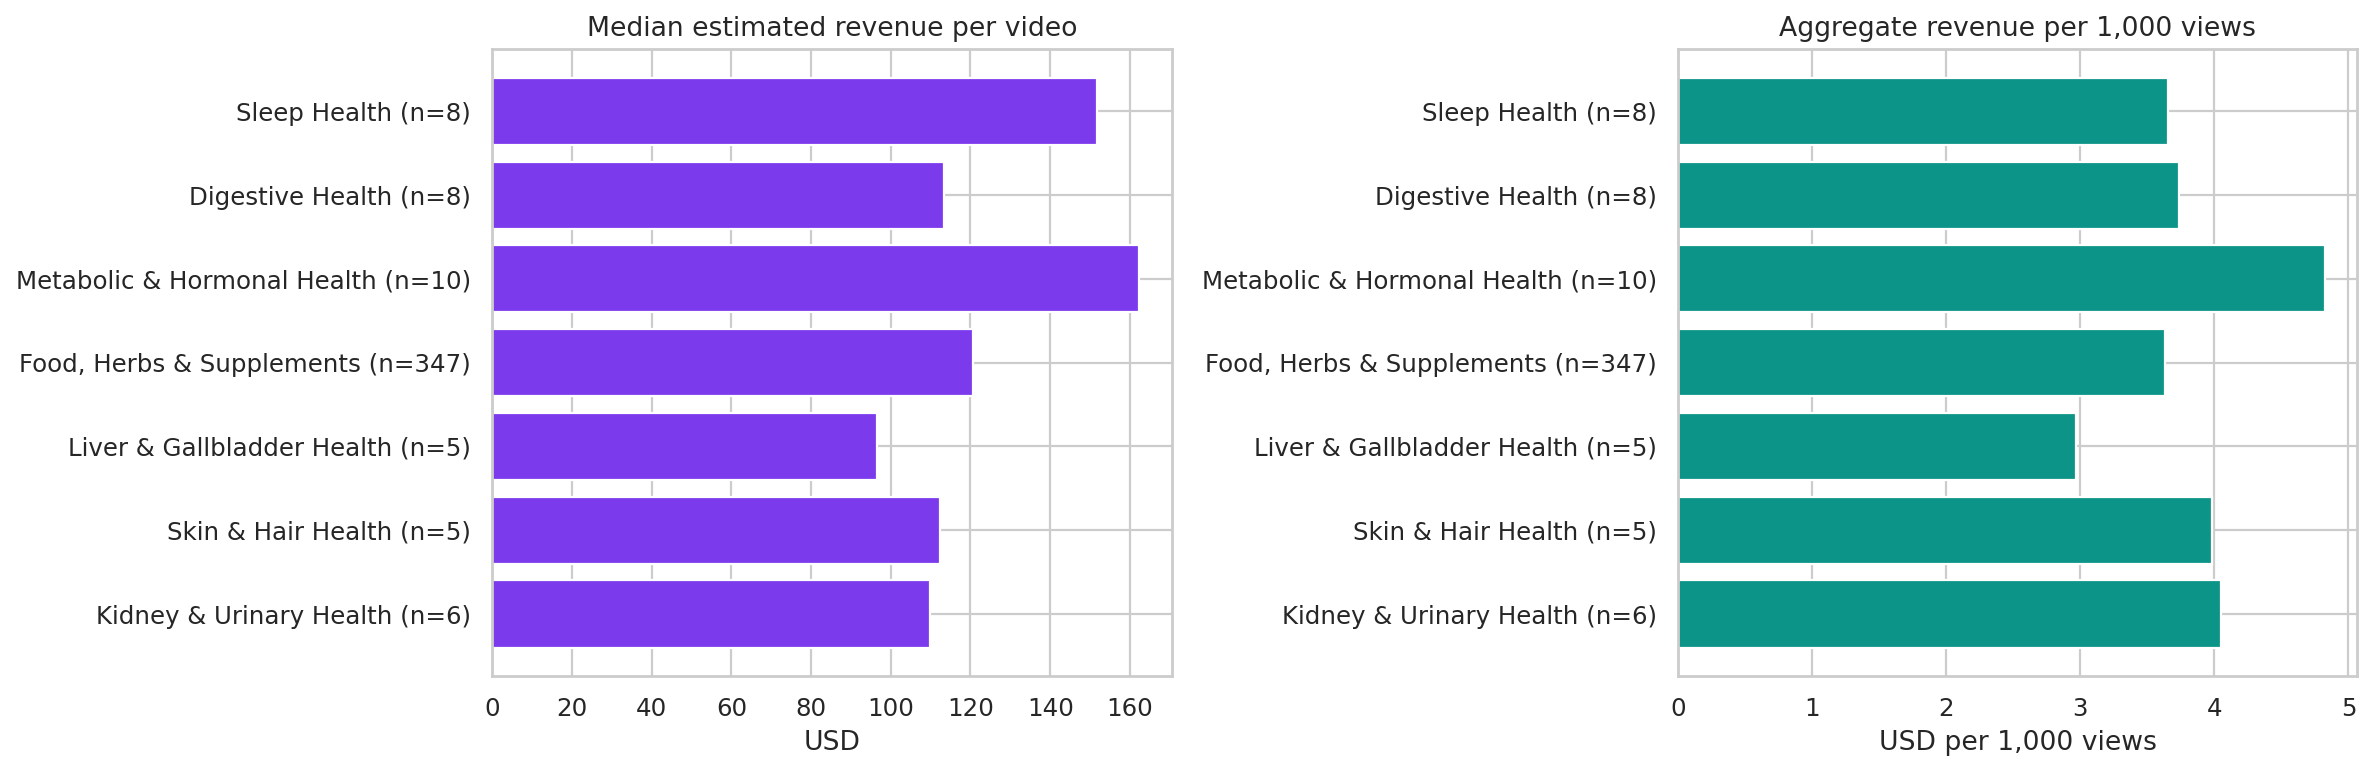

**Interpretation.** Among displayed categories, **Metabolic & Hormonal Health** has the highest aggregate computed revenue ratio (**USD 4.83 per 1,000 views**). This can reflect audience, dates, monetization conditions and content mix. It is a hypothesis for further investigation, not proof that the topic itself raises revenue.

In [17]:
if len(ranked):
    fig, axes = plt.subplots(1,2,figsize=(15,max(5,len(ranked)*.48)))
    labels = ranked.content_category + ' (n=' + ranked.video_count.astype(str) + ')'
    axes[0].barh(labels, ranked.median_revenue_usd, color='#7c3aed')
    axes[0].set(title='Median estimated revenue per video', xlabel='USD')
    axes[1].barh(labels, ranked.aggregate_revenue_per_1000_views_usd, color='#0d9488')
    axes[1].set(title='Aggregate revenue per 1,000 views', xlabel='USD per 1,000 views')
    finish_plot('07_category_monetization')
    revenue_leader = ranked.loc[ranked.aggregate_revenue_per_1000_views_usd.idxmax()]
    note(f"**Interpretation.** Among displayed categories, **{revenue_leader.content_category}** has the highest aggregate computed revenue ratio "
         f"(**USD {revenue_leader.aggregate_revenue_per_1000_views_usd:.2f} per 1,000 views**). "
         "This can reflect audience, dates, monetization conditions and content mix. It is a hypothesis for further investigation, not proof that the topic itself raises revenue.")

## 15. Median views by category within each publication year
Each bar represents a category-year group; labels show the number of videos. Groups below the display threshold appear in gray for context and should not be treated as stable winners. Categories absent in a year are absent, not zero-performing.

These are within-export publication cohorts. Comparing them does not equalize video age or establish year-over-year growth.

,publish_year,content_category,video_count,median_views,median_revenue_usd
6,2024,Sleep Health,1,44867.0,245.0810
1,2024,Digestive Health,3,41123.0,199.4660
2,2024,"Food, Herbs & Supplements",13,37588.0,169.5570
0,2024,"Bone, Joint & Muscle Health",1,29336.0,30.6090
4,2024,Liver & Gallbladder Health,3,27929.0,96.4500
5,2024,Respiratory & Immune Health,1,27842.0,129.5540
7,2024,Unclassified,11,26251.0,104.7340
8,2024,Women's Health,1,25199.0,103.4110
3,2024,Kidney & Urinary Health,1,18826.0,125.4590
17,2025,Liver & Gallbladder Health,2,138649.5,359.0740


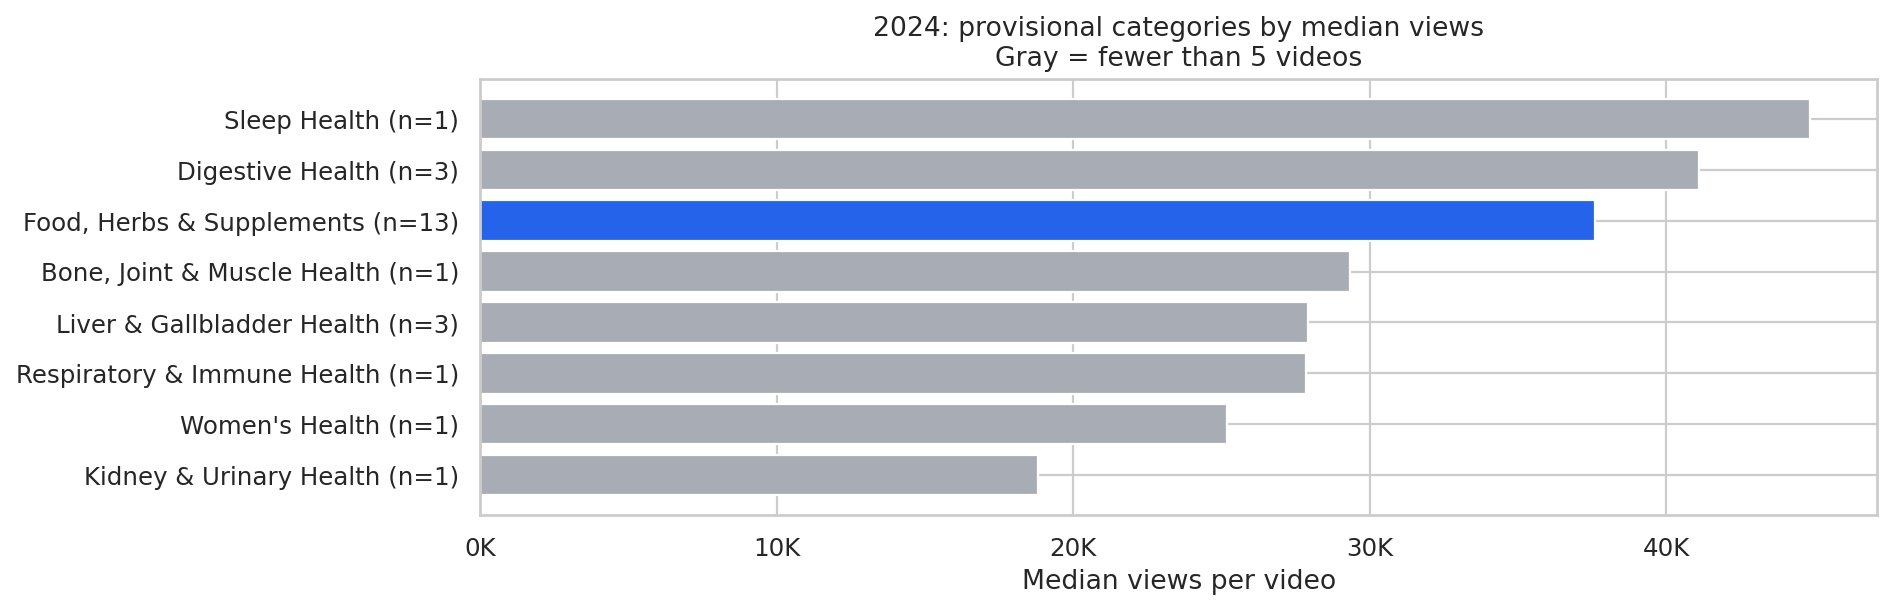

**2024 interpretation.** Among groups with n ≥ 5, **Food, Herbs & Supplements** leads by observed median views (**37,588**, n=13). Small gray groups may rank higher but provide less evidence. Year grouping does not remove within-year exposure-time differences.

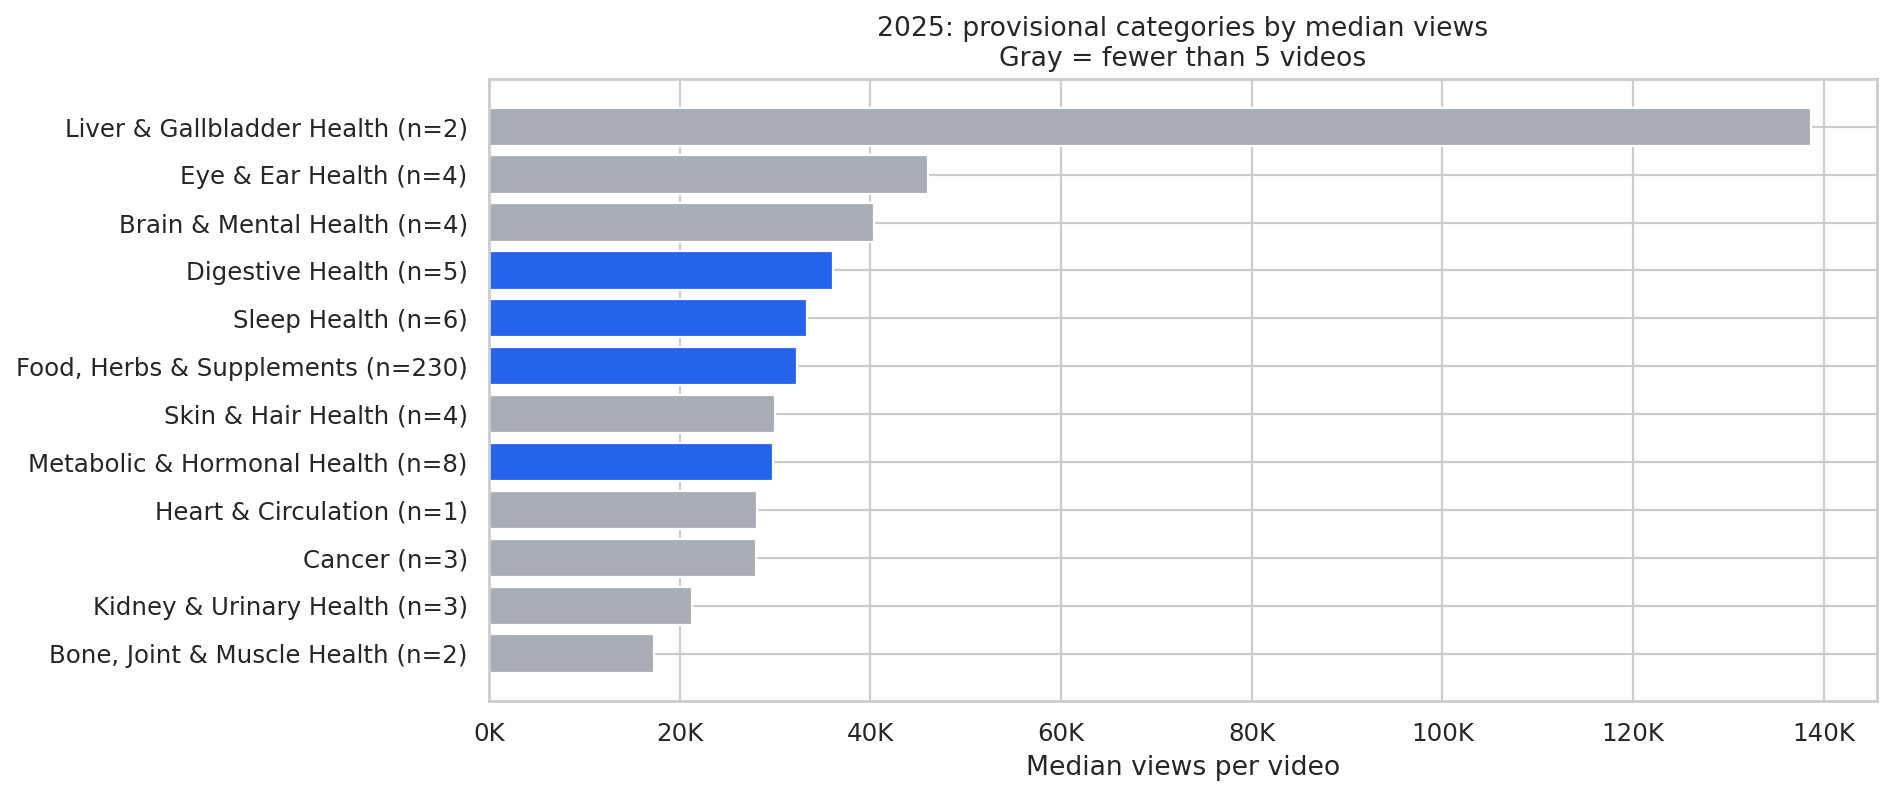

**2025 interpretation.** Among groups with n ≥ 5, **Digestive Health** leads by observed median views (**36,119**, n=5). Small gray groups may rank higher but provide less evidence. Year grouping does not remove within-year exposure-time differences.

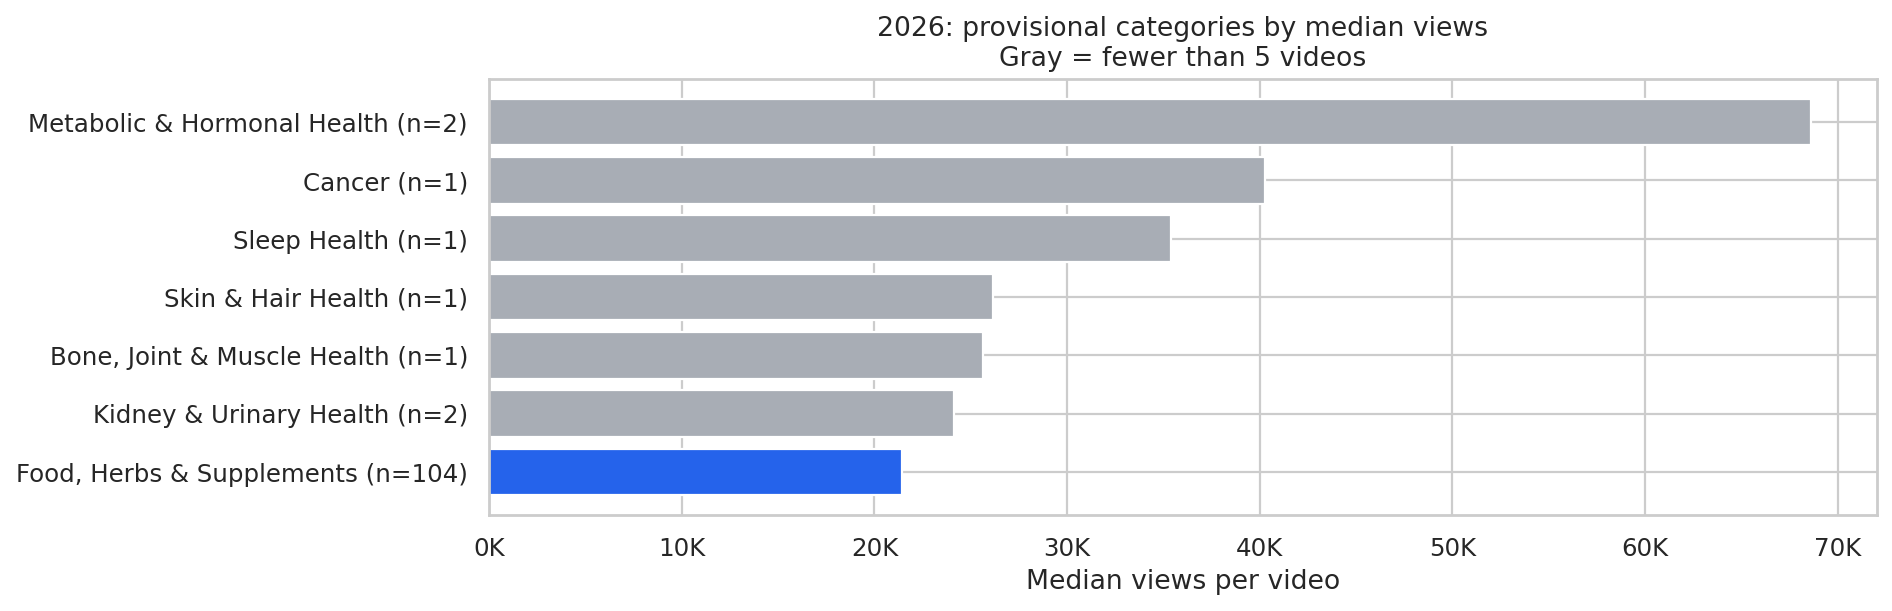

**2026 interpretation.** Among groups with n ≥ 5, **Food, Herbs & Supplements** leads by observed median views (**21,425**, n=104). Small gray groups may rank higher but provide less evidence. Year grouping does not remove within-year exposure-time differences.

In [18]:
category_year = videos_clean.groupby(['publish_year','content_category']).agg(
    video_count=('video_id','size'), median_views=('views','median'),
    median_revenue_usd=('estimated_revenue_usd','median')
).reset_index()
display(category_year.sort_values(['publish_year','median_views'], ascending=[True,False]))
for year, group in category_year.loc[category_year.content_category.ne('Unclassified')].groupby('publish_year'):
    group = group.sort_values('median_views')
    plt.figure(figsize=(12,max(4,len(group)*.43)))
    labels = group.content_category + ' (n=' + group.video_count.astype(str) + ')'
    colors = ['#2563eb' if n >= MIN_CATEGORY_N else '#a8adb5' for n in group.video_count]
    plt.barh(labels, group.median_views, color=colors)
    plt.xlabel('Median views per video')
    plt.title(f'{year}: provisional categories by median views\nGray = fewer than {MIN_CATEGORY_N} videos')
    finish_plot(f'08_category_year_{year}')
    eligible = group.loc[group.video_count >= MIN_CATEGORY_N]
    if len(eligible):
        row = eligible.iloc[-1]
        note(f"**{year} interpretation.** Among groups with n ≥ {MIN_CATEGORY_N}, **{row.content_category}** leads by observed median views "
             f"(**{row.median_views:,.0f}**, n={int(row.video_count)}). Small gray groups may rank higher but provide less evidence. "
             "Year grouping does not remove within-year exposure-time differences.")
    else:
        note(f'**{year} interpretation.** No category reaches the display threshold. Treat all rankings as small-sample descriptions.')

## 16. What the daily sheets can and cannot support
We inspect coverage and dates before using time-series data. A row dated before a video's publication may contain a structural zero. Those zeros must not be interpreted as poor video performance.

This notebook does not generalize the five selected daily series to all 498 videos, and does not use the totals sheet as a video-level join.

In [19]:
daily = daily_raw.rename(columns=column_map | {'Fecha':'date'}).copy()
daily['date'] = pd.to_datetime(daily['date'], errors='coerce')
daily['publish_date'] = pd.to_datetime(daily['publish_date'], format='mixed', errors='coerce')
daily['new_viewers'] = pd.to_numeric(daily['new_viewers'], errors='coerce')
daily_coverage = daily.groupby('video_id').agg(rows=('date','size'), first_date=('date','min'), last_date=('date','max'), publish_date=('publish_date','first')).reset_index()
display(daily_coverage)
prepub = daily.date < daily.publish_date
nonzero_prepub = int((prepub & daily.new_viewers.fillna(0).ne(0)).sum())
print('Duplicate date-video rows:', daily.duplicated(['date','video_id']).sum())
print('Rows before publication:', int(prepub.sum()))
print('Nonzero new-viewer records before publication:', nonzero_prepub)
print('Daily IDs absent from video table:', sorted(set(daily.video_id)-set(videos_clean.video_id)))
note(f"**Interpretation.** The chart sheet contains **{daily.video_id.nunique()} videos**, versus **{len(videos_clean)}** in the video table. "
     f"Its dates run from {daily.date.min():%Y-%m-%d} to {daily.date.max():%Y-%m-%d}. "
     "This date axis is recorded as evidence, but it does not independently confirm the selected metric window for the video table. "
     "A first-30-day comparison across all videos requires another export.")

,video_id,rows,first_date,last_date,publish_date
0,1L-yEOCMv3I,3818,2015-12-11,2026-05-24,2026-05-08
1,gQXwLdGldFY,3818,2015-12-11,2026-05-24,2026-05-09
2,gVxROQYr1uA,3818,2015-12-11,2026-05-24,2026-05-06
3,noj0r31-vqQ,3818,2015-12-11,2026-05-24,2026-05-05
4,zqZ3xqS1v08,3818,2015-12-11,2026-05-24,2026-05-07


**Interpretation.** The chart sheet contains **5 videos**, versus **498** in the video table. Its dates run from 2015-12-11 to 2026-05-24. This date axis is recorded as evidence, but it does not independently confirm the selected metric window for the video table. A first-30-day comparison across all videos requires another export.

Duplicate date-video rows: 0
Rows before publication: 19000
Nonzero new-viewer records before publication: 0
Daily IDs absent from video table: []


# E — Execute
## 17. Interpret findings for the CEO and define next actions
PACE Execute means communicating results and preparing usable deliverables. It does not mean that proposed actions have already been implemented.

The findings below are computed from the current file. Topic-level recommendations remain conditional on category review and scope confirmation.

In [20]:
note(f"### Executive findings — analytical draft\n"
     f"1. **Scope:** {len(videos_clean):,} exported videos contribute {videos_clean.views.sum():,.0f} views and USD {videos_clean.estimated_revenue_usd.sum():,.2f} estimated revenue. These are not reconciled whole-channel totals.\n"
     f"2. **Typical reach:** median {videos_clean.views.median():,.0f} views per video; the top 10 contribute {top10_share:.1f}% of exported views. Report medians alongside contribution.\n"
     f"3. **Viewing duration:** median computed viewing-duration percentage is {videos_clean.average_view_duration_percent.median():.1f}%. This is not a completion rate.\n"
     f"4. **Monetization:** the aggregate computed ratio is USD {aggregate_ratio:.2f} per 1,000 views. Profit and causal revenue drivers are not established.\n"
     f"5. **Classification:** {int(videos_clean.category_is_reviewed.sum())} videos are explicitly reviewed; category charts remain provisional until the review file is completed.")
if len(ranked):
    note(f"**Category hypothesis:** Review examples in **{ranked.iloc[-1].content_category}**, the leading observed median-view category among groups with at least {MIN_CATEGORY_N} videos. "
         "Check category accuracy, publication dates and within-category variation before allocating additional production effort.")

actions = pd.DataFrame([
    ['Confirm scope', 'Analyst + CEO', 'Record export dates, filters, selection method and video/live format.', 'Reconcile the subset and aggregate row before channel-level reporting.'],
    ['Validate categories', 'Analyst + content reviewer', 'Review flagged titles first, then approve or correct all remaining proposals.', 'Recompute rankings and record changes.'],
    ['Review standout videos', 'Analyst + creative team', 'Inspect high- and low-performing videos within comparable topic/date groups.', 'Document title, thumbnail and retention hypotheses; do not infer them from CTR alone.'],
    ['Collect comparable windows', 'Analyst', 'Export first-30-day metrics or daily data for all videos where available.', 'Compare equal exposure windows before choosing topic winners.'],
    ['Test content changes', 'CEO + creative team', 'Define a prospective test with an explicit outcome and comparison strategy.', 'Measure subsequent results; do not claim lift from this cross-sectional dataset.'],
    ['Publish deliverables', 'Analyst', 'Use reviewed labels and disclose sample sizes, scope and dates in Tableau.', 'Check dashboard totals against this notebook.']
], columns=['action','owner','next_step','evaluation'])
display(actions)

### Executive findings — analytical draft
1. **Scope:** 498 exported videos contribute 25,048,026 views and USD 91,752.29 estimated revenue. These are not reconciled whole-channel totals.
2. **Typical reach:** median 29,144 views per video; the top 10 contribute 18.5% of exported views. Report medians alongside contribution.
3. **Viewing duration:** median computed viewing-duration percentage is 42.8%. This is not a completion rate.
4. **Monetization:** the aggregate computed ratio is USD 3.66 per 1,000 views. Profit and causal revenue drivers are not established.
5. **Classification:** 0 videos are explicitly reviewed; category charts remain provisional until the review file is completed.

**Category hypothesis:** Review examples in **Sleep Health**, the leading observed median-view category among groups with at least 5 videos. Check category accuracy, publication dates and within-category variation before allocating additional production effort.

,action,owner,next_step,evaluation
0,Confirm scope,Analyst + CEO,"Record export dates, filters, selection method and video/live...",Reconcile the subset and aggregate row before channel-level r...
1,Validate categories,Analyst + content reviewer,"Review flagged titles first, then approve or correct all rema...",Recompute rankings and record changes.
2,Review standout videos,Analyst + creative team,Inspect high- and low-performing videos within comparable top...,"Document title, thumbnail and retention hypotheses; do not in..."
3,Collect comparable windows,Analyst,Export first-30-day metrics or daily data for all videos wher...,Compare equal exposure windows before choosing topic winners.
4,Test content changes,CEO + creative team,Define a prospective test with an explicit outcome and compar...,Measure subsequent results; do not claim lift from this cross...
5,Publish deliverables,Analyst,"Use reviewed labels and disclose sample sizes, scope and date...",Check dashboard totals against this notebook.


## 18. Prepare complete exports and SQL validation
The video-level CSV retains all original metrics (under standardized English names), derived fields, URLs, category proposals, final overrides and review metadata. It does not silently drop unclassified videos.

Tableau should use `content_category` with `review_status` visible in filters/tooltips. Use `COUNTD(video_id)` for counts and `MEDIAN(views)` for typical performance. For an aggregate revenue ratio, use `SUM(estimated_revenue_usd) / SUM(views) * 1000`; do not average category ratios together. Category-year medians must be recomputed from video rows, not averaged from yearly medians.

SQL below validates the exported rows and performs additive aggregations in a local SQLite database. The separate PostgreSQL script includes native `percentile_cont` median queries for a later PostgreSQL stage. This does not claim that PostgreSQL or Tableau has already been deployed.

In [21]:
import sqlite3

export_data = videos_clean.copy()
export_data.to_csv(processed_dir / 'youtube_long_form_tableau.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
category_draft.to_csv(processed_dir / 'video_categories_current.csv', index=False, encoding='utf-8-sig')
needs_review.to_csv(processed_dir / 'videos_needing_review.csv', index=False, encoding='utf-8-sig')
category_summary.to_csv(processed_dir / 'category_summary.csv', index=False, encoding='utf-8-sig')
category_year.to_csv(processed_dir / 'category_year_summary.csv', index=False, encoding='utf-8-sig')
correlations.to_csv(processed_dir / 'correlations.csv', index=False)
sensitivity.to_csv(processed_dir / 'correlation_sensitivity.csv', index=False)
reconciliation.to_csv(processed_dir / 'total_reconciliation.csv', index=False)
audit.to_csv(processed_dir / 'data_quality_audit.csv')

# Check the saved file, not only the in-memory dataframe.
roundtrip = pd.read_csv(processed_dir / 'youtube_long_form_tableau.csv', dtype={'video_id':'string'})
assert len(roundtrip) == len(videos_clean)
assert roundtrip.video_id.is_unique
assert set(roundtrip.video_id) == set(videos_clean.video_id)
assert roundtrip.content_category.notna().all()
assert np.isclose(roundtrip.views.sum(), videos_clean.views.sum())
assert np.isclose(roundtrip.estimated_revenue_usd.sum(), videos_clean.estimated_revenue_usd.sum())

with sqlite3.connect(processed_dir / 'youtube_long_form.sqlite') as connection:
    # This generated table is replaced on rerun. The raw workbook and review file are not overwritten.
    export_data.to_sql('videos', connection, if_exists='replace', index=False)
    sql_totals = pd.read_sql_query('SELECT COUNT(*) AS video_count, COUNT(DISTINCT video_id) AS unique_video_count, SUM(views) AS total_views, SUM(estimated_revenue_usd) AS revenue_usd FROM videos', connection)
    sql_categories = pd.read_sql_query("SELECT content_category, COUNT(*) AS video_count, SUM(views) AS total_views, SUM(estimated_revenue_usd) AS revenue_usd, 1000.0 * SUM(estimated_revenue_usd) / NULLIF(SUM(views), 0) AS aggregate_revenue_per_1000_views_usd FROM videos GROUP BY content_category ORDER BY total_views DESC", connection)
assert int(sql_totals.iloc[0].video_count) == len(videos_clean)
assert np.isclose(sql_totals.iloc[0].total_views, videos_clean.views.sum())
assert np.isclose(sql_totals.iloc[0].revenue_usd, videos_clean.estimated_revenue_usd.sum())
display(sql_totals)
display(sql_categories.round(3))
print('CSV round-trip and SQL aggregate checks passed.')
print('Output directory:', processed_dir)

,video_count,unique_video_count,total_views,revenue_usd
0,498,498,25048026,91752.294


,content_category,video_count,total_views,revenue_usd,aggregate_revenue_per_1000_views_usd
0,"Food, Herbs & Supplements",347,18488349,67151.426,3.632
1,Unclassified,90,3364282,12220.161,3.632
2,Sleep Health,8,858014,3134.070,3.653
3,Metabolic & Hormonal Health,10,431313,2081.187,4.825
4,Eye & Ear Health,4,388082,1492.741,3.846
5,Liver & Gallbladder Health,5,369628,1098.523,2.972
6,Kidney & Urinary Health,6,307475,1244.577,4.048
7,Digestive Health,8,251137,937.813,3.734
8,Brain & Mental Health,4,167933,786.032,4.681
9,Skin & Hair Health,5,135557,540.206,3.985


CSV round-trip and SQL aggregate checks passed.
Output directory: /workspace/scratch/790c83805521/deliverables/youtube-long-form-performance-analysis/data/processed


## 19. Handoff and remaining work
**Completed in this draft:** workbook inventory; type conversion; quality checks; total reconciliation; derived metrics; distributions; correlation and sensitivity analysis; publication cohorts; transparent draft taxonomy; category and category-year comparisons; daily-sheet coverage audit; complete CSV exports; SQLite execution and validation.

**Requires Marco's input:**
- Confirm reporting dates, filters, extraction selection and whether any records are livestreams.
- Review the category table. No title-only suggestion has been represented as a verified video review.
- Approve the taxonomy or add more useful subcategories if the broad food/ingredient group hides important distinctions.
- Confirm publication permissions before exposing financial or audience data in a public portfolio.

**Future work:** equal-window comparisons; validated category sensitivity; optional matched comparison to Shorts after aligning definitions and scope; PostgreSQL import; Tableau dashboard and executive presentations after review. These are not claimed as completed here.

### Suggested Tableau views
1. Overview: exported-video count, subset views, subset revenue and median views.
2. Content topics: median views, video count, review status and publication-year filter.
3. Monetization: category contribution and aggregate revenue per 1,000 views.
4. Viewing duration: video length, absolute average seconds and relative percentage.
5. Methodology: source scope, provisional labels and limitations.

### Reproducibility and interpretation
Run the notebook top to bottom. Preserve `category_review.csv` between runs. Inspect any changed source schema or failed assertion rather than bypassing it. When reviewed categories change, rerun category cells and exports. Recompute medians from video-level records for every filter selection. Correlations, rankings and this dataset do not establish causal content effects.